# The latent country in J-space — latent bridge v2, model-agnostic, with paired bootstrap intervals

**Question.** How much of the residual stream lies in the J-space (sparse non-negative
combinations of J-lens vectors, as Anthropic define it), where in depth is it active, and is the
J-space component that carries a latent country (*Japan* in *"Toyota is a company from a country
where the main language is"*) the same across prompts, and the same as when the country is
named? How much of a difference-of-means probe direction lies in J-space (the paper reports
10–15% for its intermediate-concept probes)? This is the model-agnostic version of
[the GPT-2 XL notebook](../gpt2-xl/latent_bridge_v2/latent_bridge_v2_jspace.ipynb): any
`from_hf` model with a matching lens, all 530 latent-bridge candidates, token positions from
tokenizer offsets, and paired bootstrap intervals for the per-prompt comparisons.

**Answer/status.** The saved outputs are an executed tiny, untrained model with identity
Jacobians. They validate the pipeline (J-lens and logit-lens arms coincide, so their paired
differences are exactly zero and flagged `degenerate`), not trained-model results. Set
`RUN_MODE="pretrained"` for a model run, or `RUN_MODE="cache"` with `EXISTING_CACHE` pointing at
a saved `results.pkl` for CPU-only reanalysis without model, lens or tokenizer downloads.

## Method

**J-space** ([Verbalizable Representations Form a Global Workspace](https://transformer-circuits.pub/2026/workspace/index.html),
Methods: The J-Space). The J-lens vectors at layer l are `v_t = J_lᵀ C(γ ⊙ u_t)`: the
unembedding row of token t with the final norm's gain folded in, centred for LayerNorm and not
for RMSNorm (`jlens.workspace.lens_directions` decides this per model), pulled back through
`J_l`. One atom per tokenizer vocabulary ID (padding rows of a larger output head are left
out), unit-normalized. The J-space component of `h` is its nearest sparse non-negative
combination of at most K atoms, found by `jlens.workspace.jspace_pursuit`: K greedy steps, each
adding the atom most positively correlated with the residual, each followed by a non-negative
least-squares refit of the whole support (`REFIT_STEPS` projected-gradient steps). K runs to
`K_MAX = 64`; the headline uses the paper's K = 25, fixed in advance.

**Controls.** (1) *K random directions* explain `K/d` of `‖h‖²` in expectation. (2) *The
logit-lens dictionary* (`J_l = I`), same pursuit. (3) *Best of V random atoms*: the same pursuit
over as many random unit directions as the J dictionary has atoms; each pick is the luckiest of
V, worth about `2 ln V / d` of the norm.

**Metrics** (per row, then averaged).
* **Fraction of norm** `‖h_J‖² / ‖h‖²` against K. **Occupancy** (the paper's criterion): the
  first K at which adding a J atom improves the reconstruction less than a random direction
  (`1/d`), censored at `K_MAX`; median over rows, then over the layers of a band. Also against
  the marginal gain of the best-of-V random pursuit.
* **Country atom**: is a whole-token spelling of the country (`DecodedSpellings`: case and
  leading-space variants) among the K selected atoms; control: the prompt's control country.
* **Consistency across prompts**, per row: mean cosine to rows with the same country minus mean
  cosine to rows with a different country, counting only rows from *different* subject families
  (Toyota vs Osaka vs sushi). Restricted to the countries whose language another country shares
  (Spain / Mexico / Peru, Brazil / Portugal): same country minus *different country, same
  language*, which isolates the country from the answer language.
* **Named vs latent**: the component at the country token of the 20 neutral templates of
  `concept-probe-templates.json` (*"Let me tell you about Japan."*) is averaged per country;
  each latent row is assigned the country whose named centroid is most similar (cosine). Top-1
  among 22 (chance 1/22) and within the language group (chance about 0.39).
* **Probes in J-space**: the fraction of each difference-of-means probe `w_c` (mean over the
  named templates minus the mean over countries, as in `latent_bridge_v2_swap.ipynb`) explained
  by its J-space component.

The last four are computed for the J-space component, the logit-lens and random-atom
components, the full residual `h` and the non-J part `h − h_J`, which are the paired arms below.

**Where.** Fixed positions, located with tokenizer character offsets
(`jlens.position_benchmark.latent_bridge_spans`, `jlens.concept_probes.prepare_probe_examples`):
the last subject token, the last token of `country`, the last prompt token, and the last token
of the named country in the templates. Five bands of block outputs from 1/6 of the depth to the
last inner block (GPT-2 XL: 8–16, 16–24, 24–32, 32–40, 40–47, as in the GPT-2 notebook); the
final block is excluded. Activations are used as they are (`raw`), and mean-centred per layer
and position type (`centred`) to check that outlier dimensions do not drive the result.

**Uncertainty.** Paired percentile intervals (`jlens.bootstrap.paired_cluster_bootstrap`):
resample latent prompts with replacement, the same draws for every arm, the difference computed
on each draw. They are conditional on the fixed model, lens, named centroids and reference rows,
and pointwise (not corrected for the many bands, positions and metrics shown).

## Changes from the GPT-2 XL notebook, and notes on it

* **Model-agnostic plumbing.** No `transformer.ln_f`, `n_embd`, `" country"` token lookups or
  single-token assumptions: the final-norm gain and centering come from
  `lens_directions(mode="logit")`, positions from character offsets, the BOS policy is explicit
  (`ExplicitPromptModel`), and countries without a whole-token spelling are reported as
  unsupported for the atom metrics instead of failing an assertion.
* **All 530 candidates.** The GPT-2 notebook kept the 354 prompts GPT-2 XL answered correctly; that
  selection does not transfer to other models. The headline uses all candidates, with the
  current model's correct subset and the historical GPT-2 subset reported beside it.
* **One pass per prompt, model freed before the pursuit.** The GPT-2 notebook ran each of the
  three latent positions as a separate row of the forward pass and ran the model twice (§2 and
  §7), and kept GPT-2 XL in fp32 on the GPU during the pursuit; its committed output shows about
  forty CUDA out-of-memory retries on the 16 GB V100. Here each prompt runs once, all positions
  are gathered from it, and the model is deleted before three V×d dictionaries are built.
* **Pursuit.** The library pursuit refits the non-negative coefficients to convergence (300
  projected-gradient steps) instead of three line-search steps, so the fractions of norm are a
  little higher and the marginal gains behind the occupancy are not distorted by coefficients
  still catching up from earlier steps. Numbers are therefore close to, not identical to, the
  GPT-2 notebook.
* **Fixed K.** The GPT-2 notebook reported concept metrics at the grid K closest to each band's
  median occupancy (32 raw; for the centred variant it hit the cap of 64, i.e. the occupancy is
  censored there). Here the headline K is the paper's 25, chosen in advance; the whole grid is
  shown as a sensitivity table.
* **Per-row consistency.** Pairwise cosines are averaged within each row first (same-country
  partners minus different-country partners), then over rows, so each prompt is one bootstrap
  unit. The GPT-2 notebook averaged over all pairs at once; the two weightings differ slightly.
  The row values depend on the other rows, so their intervals condition on the reference set.
* **Probes.** The probe directions are rebuilt here from the named-template activations of this
  run (the same definition as `latent_bridge_v2_swap.ipynb`), so no file from another notebook is
  needed. They come from prompts that *name* the country; the paper's probes come from prompts
  that imply the intermediate, so the 10–15% comparison is indicative only.
* **Notes on the GPT-2 result itself.** Its occupancy against the best-of-50257 random control
  is 0–5, so "J-space" there is a statement about *which* directions, not about how much norm;
  and from layer 32 on, the probe vectors are no more J-aligned than 25 lucky random atoms. Both
  points carry over and are reported again here.

In [1]:
import hashlib
import json
import os
import subprocess
import sys
import warnings
from pathlib import Path

REPO_URL = "https://github.com/ai360-project-school-j-lens/jacobian-lens-gpt2.git"
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules

# Reuse a checkout when opened locally, including from a nested notebook folder.
local_repo = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "jlens" / "evaluation.py").is_file()),
    None,
)
REPO_DIR = local_repo or Path.cwd() / "jacobian-lens-gpt2"
if local_repo is not None:
    if IN_COLAB:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
elif REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

REPO = REPO_DIR.resolve()
if IN_COLAB:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO)], check=True,
    )
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
if "def jspace_pursuit" not in (REPO / "jlens" / "workspace.py").read_text():
    raise RuntimeError("Update this checkout to the revision containing jlens.workspace.jspace_pursuit.")
print(f"Repository ready: {REPO.name}")

Repository ready: jlens-jspace


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
from IPython.display import Markdown, display
from tqdm.auto import tqdm
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer

import jlens
from jlens.bootstrap import paired_cluster_bootstrap
from jlens.concept_probes import prepare_probe_examples
from jlens.evaluation import identity_lens
from jlens.hooks import ActivationRecorder
from jlens.position_benchmark import latent_bridge_spans, load_latent_bridge
from jlens.strict_scoring import DecodedSpellings, ExplicitPromptModel
from jlens.workspace import final_norm_centers, jspace_pursuit, lens_directions

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)

## Configuration and cache-only mode

`smoke` is an offline check on a tiny random Llama with identity Jacobians. `pretrained` loads
`MODEL_ID` and its lens: a pinned Neuronpedia file for the models in `HUB_LENS_FILES`, otherwise
`LENS_PATH` (GPT-2 XL: the WikiText lens of
[wikitext_lens_fit.ipynb](../gpt2-xl/jacobian_lens/wikitext_lens_fit.ipynb)). `cache` reads an
earlier `results.pkl` of this notebook and makes no Hub requests; its manifest supplies the model
identity. The run directory is keyed by a manifest of the prompts, model and tokenizer, lens
digest, pursuit settings, implementation files and notebook code; a cache hit skips the model
and the pursuit. Bootstrap settings are not part of that key.

In [3]:
RUN_MODE = os.environ.get("JLENS_JSPACE_MODE", "smoke")  # "smoke", "cache", or "pretrained"
EXISTING_CACHE = os.environ.get("JLENS_JSPACE_CACHE", "")  # results.pkl of an earlier run
MODEL_ID = os.environ.get("JLENS_MODEL_ID", "openai-community/gpt2-xl")
MODEL_REVISION = os.environ.get("JLENS_MODEL_REVISION", "main")  # Pin a Hub commit to reproduce.
LENS_PATH = Path(os.environ.get(
    "JLENS_LENS_PATH", REPO / "runs/gpt2-xl-wikitext/gpt2-xl_jacobian_lens.pt",
)).expanduser()
# Same pinned artifacts as the model-agnostic benchmark and token-swap notebooks.
HUB_LENS_FILES = {
    "Qwen/Qwen3-4B": "qwen3-4b/jlens/Salesforce-wikitext/Qwen3-4B_jacobian_lens.pt",
    "Qwen/Qwen3-1.7B": "qwen3-1.7b/jlens/Salesforce-wikitext/Qwen3-1.7B_jacobian_lens.pt",
    "openai-community/gpt2": "gpt2-small/jlens/Salesforce-wikitext/gpt2_jacobian_lens.pt",
    "google/gemma-4-31B": "gemma-4-31b/jlens/Salesforce-wikitext/gemma-4-31B_jacobian_lens.pt",
    "google/gemma-4-E4B": "gemma-4-e4b/jlens/Salesforce-wikitext/gemma-4-E4B_jacobian_lens.pt",
    "Qwen/Qwen3.5-9B-Base": "qwen3.5-9b-pt/jlens/Salesforce-wikitext/Qwen3.5-9B-Base_jacobian_lens.pt",
    "Qwen/Qwen3.5-4B": "qwen3.5-4b/jlens/Salesforce-wikitext/Qwen3.5-4B_jacobian_lens_n1000.pt",
}
HUB_LENS = (
    dict(repo_id="neuronpedia/jacobian-lens", filename=HUB_LENS_FILES[MODEL_ID],
         revision="9fa267f841d62aa468dab5b9b38c3dc45a82d863")
    if MODEL_ID in HUB_LENS_FILES else None
)
LENS_SOURCE = "hub" if HUB_LENS is not None and not os.environ.get("JLENS_LENS_PATH") else "local"
FIT_PROVENANCE = {
    "model_id": MODEL_ID,
    "model_revision": None,
    "dtype": "unknown",
    "corpus_mix": "unknown: fill from the fit manifest",
    "sequence_length": None,
    "dimension_batch_size": None,
}
# Keep GPT-2 BOS behavior; other presets use their native tokenizer policy.
BOS_POLICY = "prepend" if MODEL_ID.startswith("openai-community/gpt2") else "tokenizer"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float32
BATCH_SIZE = 16
MAX_SEQ_LEN = 128
ROW_CHUNK = 1024  # rows per pursuit call: bounds [rows, K_MAX, d] atoms and [rows, vocab] scores
K_MAX = 64
K_GRID = [2, 4, 8, 16, 25, 32, 64]
K_HEADLINE = 25  # the paper's K, fixed in advance
REFIT_STEPS = 300  # projected-gradient steps per non-negative refit
DICTIONARIES = ["J-lens", "logit lens", "random"]
ARMS = [*DICTIONARIES, "full h", "non-J part"]
VARIANTS = ["raw", "centred"]
POSITIONS = ["subject", "country token", "last", "named"]
LATENT_POSITIONS = POSITIONS[:3]
SMOKE_SUBJECTS_PER_COUNTRY = 2
SEED = 0
CACHE_ROOT = REPO / "runs/model-agnostic-latent-bridge-jspace"
FORCE_RECOMPUTE = False
BOOTSTRAP_OPTIONS = dict(
    n_resamples=int(os.environ.get("JLENS_BOOTSTRAP_RESAMPLES", "10000")),
    confidence=0.95, seed=0, batch_size=256,
)
COLORS = {"J-lens": "#2a78d6", "logit lens": "#eb6834", "random": "#52514e", "probe": "#1b9e5a",
          "full h": "#8c8c8c", "non-J part": "#c49c94"}
LABELS = {"J-lens": "J-space component", "logit lens": "logit-lens component",
          "random": "random-atom component", "full h": "full h", "non-J part": "non-J part"}

if RUN_MODE not in {"smoke", "cache", "pretrained"}:
    raise ValueError("RUN_MODE must be smoke, cache, or pretrained")
if K_HEADLINE not in K_GRID or max(K_GRID) > K_MAX:
    raise ValueError("K_HEADLINE must be in K_GRID, and K_GRID within K_MAX")

In [4]:
latent_evals = load_latent_bridge(REPO)
pool = json.loads((REPO / "data/experiments/latent-bridge-v2-candidates.json").read_text())
LANG = pool["languages"]
COUNTRIES = sorted(LANG)
TEMPLATES = json.loads((REPO / "data/experiments/concept-probe-templates.json").read_text())["templates"]
full_counts = {name: len(items) for name, items in latent_evals.items()}
if RUN_MODE == "smoke":
    # Controls were chosen on the full candidate list; keep a few subjects per country.
    def smoke_subset(items):
        kept, seen = [], {}
        for item in items:
            country = item["intermediates"][0]
            if seen.get(country, 0) < SMOKE_SUBJECTS_PER_COUNTRY:
                kept.append(item)
                seen[country] = seen.get(country, 0) + 1
        return kept

    latent_evals = {name: smoke_subset(items) for name, items in latent_evals.items()}

CACHED_PAYLOAD = None
if RUN_MODE == "cache":
    if not EXISTING_CACHE:
        raise ValueError("Set EXISTING_CACHE to a results.pkl of this notebook")
    SOURCE_CACHE_PATH = Path(EXISTING_CACHE).expanduser().resolve()
    CACHED_PAYLOAD = pd.read_pickle(SOURCE_CACHE_PATH)
    required = {"manifest", "evals", "templates", "sites", "rows", "layers", "bands"}
    if not isinstance(CACHED_PAYLOAD, dict) or required - set(CACHED_PAYLOAD):
        raise ValueError("Expected a complete results.pkl of this notebook")
    latent_evals, TEMPLATES = CACHED_PAYLOAD["evals"], CACHED_PAYLOAD["templates"]


def digest_json(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()


EVALS_SHA256 = digest_json({"latent": latent_evals, "templates": TEMPLATES, "languages": LANG})
if RUN_MODE == "cache" and EVALS_SHA256 != CACHED_PAYLOAD["manifest"]["evals_sha256"]:
    raise ValueError("Prompts changed since this cache; restore the matching source data")
SHARED_COUNTRIES = [c for c in COUNTRIES if sum(LANG[o] == LANG[c] for o in COUNTRIES) > 1]
display(pd.DataFrame([
    {"family": name.split("/", 1)[1], "template": items[0]["prompt"].replace(items[0]["subject"], "{X}", 1)
     if items else "", "candidates": full_counts.get(name), "selected": len(items),
     "countries": len({item["intermediates"][0] for item in items}),
     "historical GPT-2 kept": sum(item["gpt2_kept"] for item in items)}
    for name, items in latent_evals.items()
]).set_index("family"))
print(f"{len(COUNTRIES)} countries; shared-language countries: {', '.join(SHARED_COUNTRIES)}; "
      f"{len(TEMPLATES)} named templates")

,template,candidates,selected,countries,historical GPT-2 kept
family,,,,,
landmark,The Eiffel Tower is in a country where the mai...,108,44,22,31
city,{X} is a city in a country where the main lang...,119,44,22,38
person,{X} was born in a country where the main langu...,117,44,22,32
brand,{X} is a company from a country where the main...,83,36,20,19
food,Croissant comes from a country where the main ...,103,42,21,18


22 countries; shared-language countries: Brazil, Mexico, Peru, Portugal, Spain; 20 named templates


In [5]:
if RUN_MODE == "cache":
    LENS_PROVENANCE = CACHED_PAYLOAD["manifest"].get("lens_artifact", {})
    RESOLVED_LENS_PATH = None
    print("Cache-only: lens loading skipped.")
else:
    from jlens.artifact_provenance import download_lens_artifact

    # Clear a previous resolution before a failed or interrupted rerun.
    RESOLVED_LENS_PATH = None
    LENS_PROVENANCE = None
    if RUN_MODE == "smoke":
        LENS_PROVENANCE = {"source": "identity", "fitting_provenance": "no fitting"}
    else:
        if FIT_PROVENANCE["model_id"] != MODEL_ID:
            raise ValueError("Lens provenance model_id differs from MODEL_ID")
        if LENS_SOURCE == "hub":
            if not HUB_LENS:
                raise ValueError(f"No Hub preset for {MODEL_ID}; supply HUB_LENS or use a local lens.")
            artifact = download_lens_artifact(**HUB_LENS)
            RESOLVED_LENS_PATH = Path(artifact.path)
            LENS_PROVENANCE = {"source": "hub", **artifact.to_dict()}
        elif LENS_SOURCE == "local":
            local_path = Path(LENS_PATH).expanduser().resolve()
            if not local_path.is_file():
                raise FileNotFoundError(f"Set LENS_PATH to a fitted lens for {MODEL_ID}: {local_path}")
            RESOLVED_LENS_PATH = local_path
            LENS_PROVENANCE = {"source": "local", "path": str(local_path),
                               "fitting_provenance": "user-supplied; see FIT_PROVENANCE"}
        else:
            raise ValueError("LENS_SOURCE must be hub or local")
    display(LENS_PROVENANCE)

{'source': 'identity', 'fitting_provenance': 'no fitting'}

## Model identity and cache provenance

Cached `.pkl` files and figures live in the ignored `runs/` directory. In cache mode nothing is
loaded: the stored sites already carry their decoded tokens.

In [6]:
import re

from huggingface_hub import HfApi


def digest_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


NOTEBOOK_PATH = REPO / "notebooks/model_agnostic/latent_bridge_v2_jspace_bootstrap.ipynb"
RUN_CELLS = {"jspace-repository-setup", "jspace-config", "jspace-data", "jspace-lens-source",
             "jspace-identity", "jspace-helpers", "jspace-run"}
if RUN_MODE == "cache":
    manifest = CACHED_PAYLOAD["manifest"]
    SOURCE_MODE = manifest["mode"]
    run_model_id, resolved_revision = manifest["model"], manifest["revision"]
    run_dtype, BOS_POLICY = manifest["dtype"], manifest["bos_policy"]
    tokenizer = config = None
    CACHE_PATH = SOURCE_CACHE_PATH
    RUN_DIR = CACHE_PATH.parent / "reanalysis"  # keep the source cache directory unmodified
    RUN_DIR.mkdir(exist_ok=True)
    print(f"Cache-only source: {SOURCE_MODE}; model: {run_model_id}; revision: {resolved_revision}")
else:
    if RUN_MODE == "smoke":
        from tokenizers import Tokenizer, models, pre_tokenizers
        from transformers import LlamaConfig, PreTrainedTokenizerFast

        # Words and punctuation as separate tokens, so every span has clean offsets.
        splitter = pre_tokenizers.Whitespace()
        texts = [item["prompt"] for items in latent_evals.values() for item in items]
        texts += [template.format(x=country) for template in TEMPLATES for country in COUNTRIES]
        texts += [*COUNTRIES, *LANG.values()]
        pieces = {piece for text in texts for piece, _ in splitter.pre_tokenize_str(text)}
        vocab = {token: i for i, token in enumerate(["[UNK]", "[BOS]", "[PAD]", *sorted(pieces)])}
        backend = Tokenizer(models.WordLevel(vocab, unk_token="[UNK]"))
        backend.pre_tokenizer = splitter
        tokenizer = PreTrainedTokenizerFast(
            tokenizer_object=backend, unk_token="[UNK]", bos_token="[BOS]", pad_token="[PAD]",
        )
        config = LlamaConfig(
            vocab_size=len(tokenizer), hidden_size=64, intermediate_size=128,
            num_hidden_layers=6, num_attention_heads=4, num_key_value_heads=2,
            max_position_embeddings=MAX_SEQ_LEN, bos_token_id=tokenizer.bos_token_id,
            pad_token_id=tokenizer.pad_token_id, eos_token_id=None,
        )
        run_model_id, resolved_revision = "offline/random-tiny-llama", "seed-0"
        lens_identity = "identity-matrices-v1"
        fit_metadata = {"method": "identity; no fitting", "corpus_mix": None,
                        "sequence_length": None, "dimension_batch_size": None}
        run_dtype = torch.float32
    else:
        # Resolve before loading so config, tokenizer and weights share one commit.
        resolved_revision = HfApi().model_info(MODEL_ID, revision=MODEL_REVISION).sha
        if not isinstance(resolved_revision, str) or not re.fullmatch(r"[0-9a-f]{40}", resolved_revision):
            raise ValueError("The Hub did not return an immutable model revision")
        config = AutoConfig.from_pretrained(MODEL_ID, revision=resolved_revision)
        tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=resolved_revision, use_fast=True)
        if FIT_PROVENANCE["model_revision"] not in {None, resolved_revision}:
            raise ValueError("Lens provenance revision differs from the selected model")
        run_model_id = MODEL_ID
        lens_identity = (LENS_PROVENANCE["sha256"] if LENS_SOURCE == "hub"
                         else digest_file(RESOLVED_LENS_PATH))
        fit_metadata = FIT_PROVENANCE.copy()
        run_dtype = DTYPE
    if not tokenizer.is_fast:
        raise ValueError("This notebook requires fast-tokenizer offsets for its token positions")

    implementation = [
        "jlens/workspace.py", "jlens/position_benchmark.py", "jlens/concept_probes.py",
        "jlens/strict_scoring.py", "jlens/hf.py", "jlens/hooks.py", "jlens/lens.py",
        "jlens/evaluation.py",
    ]
    notebook_code = ["".join(cell["source"]) for cell in json.loads(NOTEBOOK_PATH.read_text())["cells"]
                     if cell["cell_type"] == "code" and cell["id"] in RUN_CELLS]
    manifest = {
        "schema": 1, "mode": RUN_MODE, "model": run_model_id, "revision": resolved_revision,
        "config": config.to_dict(), "tokenizer": tokenizer.backend_tokenizer.to_str(),
        "special_tokens": tokenizer.special_tokens_map, "bos_policy": BOS_POLICY,
        "dtype": str(run_dtype), "device": DEVICE, "lens_sha256_or_identity": lens_identity,
        "lens_artifact": {k: v for k, v in LENS_PROVENANCE.items() if k != "path"},
        "fit": fit_metadata, "evals_sha256": EVALS_SHA256,
        "implementation": {name: digest_file(REPO / name) for name in implementation},
        "notebook_code_sha256": digest_json(notebook_code),
        "versions": {"torch": torch.__version__, "transformers": transformers.__version__,
                     "numpy": np.__version__, "pandas": pd.__version__},
        "matmul_precision": torch.get_float32_matmul_precision(),
        "batch_size": BATCH_SIZE, "max_seq_len": MAX_SEQ_LEN, "k_max": K_MAX, "k_grid": K_GRID,
        "refit_steps": REFIT_STEPS, "variants": VARIANTS, "seed": SEED,
        "dictionary": "unit rows of C(gain * u_t) J_l over tokenizer vocabulary IDs",
    }
    RUN_DIR = CACHE_ROOT / digest_json(manifest)[:20]
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    CACHE_PATH = RUN_DIR / "results.pkl"
    (RUN_DIR / "lens_provenance.json").write_text(json.dumps(LENS_PROVENANCE, indent=2) + "\n")
    (RUN_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str) + "\n")
    print(f"Mode: {RUN_MODE}; model: {run_model_id}; revision: {resolved_revision}")
    print(f"Cache: {CACHE_PATH.relative_to(REPO)}")
    print("Fitting provenance:", fit_metadata)
    SOURCE_MODE = RUN_MODE

Mode: smoke; model: offline/random-tiny-llama; revision: seed-0
Cache: runs/model-agnostic-latent-bridge-jspace/e3c45d76e265b3a8e90f/results.pkl
Fitting provenance: {'method': 'identity; no fitting', 'corpus_mix': None, 'sequence_length': None, 'dimension_batch_size': None}


## Sites, activations and decompositions

Sites are `(prompt, position)` rows. Each distinct prompt runs once, length-sorted and
right-padded with an attention mask when the adapter supports one (otherwise equal-length
batches); every site is read at its own position, and the model's top-1 answer is read from the
final block at the last real token. Then the unembedding with the final norm folded in is kept,
the model is deleted, and per layer the pursuit runs over all rows for each dictionary and
variant. Per-row metrics are stored for every layer, K of the grid and arm (`rows`), so tables,
bootstrap intervals and plots are rebuilt from the cache without a model.

In [7]:
def depth_bands(n_layers):
    """Five bands of block outputs from 1/6 of the depth to the last inner block.

    Half-open; GPT-2 XL (48 blocks) gives 8-16, 16-24, 24-32, 32-40, 40-47. Empty bands of
    very shallow models are dropped.
    """
    edges = [round(n_layers * i / 6) for i in range(1, 6)] + [n_layers - 1]
    return {f"{lo}-{hi}": list(range(lo, hi)) for lo, hi in zip(edges[:-1], edges[1:], strict=True) if hi > lo}


def site_rows(model, latent_evals, templates):
    """Latent sites from offsets of each prompt; named sites from offsets of each template."""
    rows = []
    for dataset, items in latent_evals.items():
        for item in items:
            ids = model.encode_ids(item["prompt"], max_length=MAX_SEQ_LEN)
            spans = latent_bridge_spans(model, item, max_seq_len=MAX_SEQ_LEN)
            for position in LATENT_POSITIONS:
                index = spans[position][-1]
                rows.append(dict(
                    prompt_id=f"{dataset}:{item['name']}", family=item["family"], subject=item["subject"],
                    country=item["intermediates"][0], control=item["controls"][0], target=item["target"],
                    gpt2_kept=item["gpt2_kept"], position=position, index=index, ids=ids,
                    token=model.tokenizer.decode([ids[index]]),
                ))
    frame = pd.DataFrame([dict(template_id=i, template=t, prefix=t.split("{x}")[0], suffix=t.split("{x}")[1])
                          for i, t in enumerate(templates)])
    examples = prepare_probe_examples(model, COUNTRIES, frame, max_length=MAX_SEQ_LEN)
    for row in examples[examples.valid].itertuples():
        c = COUNTRIES.index(row.concept)
        rows.append(dict(
            prompt_id=f"named:{row.concept}:{row.template_id}", family="named",
            subject=f"template {row.template_id}", country=row.concept,
            control=COUNTRIES[(c + len(COUNTRIES) // 2) % len(COUNTRIES)], target=LANG[row.concept],
            gpt2_kept=False, position="named", index=row.position, ids=list(row.input_ids),
            token=model.tokenizer.decode([row.input_ids[row.position]]),
        ))
    return pd.DataFrame(rows), examples


def row_groups(sites):
    """Integer tensors for the per-row metrics."""
    languages = sorted(set(LANG.values()))
    country_language = torch.tensor([languages.index(LANG[c]) for c in COUNTRIES])
    return dict(
        country=torch.tensor(sites.country.map(COUNTRIES.index).to_numpy()),
        control=torch.tensor(sites.control.map(COUNTRIES.index).to_numpy()),
        family=torch.tensor(pd.factorize(sites.family)[0]),
        position=torch.tensor(sites.position.map(POSITIONS.index).to_numpy()),
        language=country_language[torch.tensor(sites.country.map(COUNTRIES.index).to_numpy())],
        country_language=country_language,
        shared=torch.bincount(country_language)[country_language] > 1,  # [country]
    )


def masked_mean(values, mask):
    """Row means of values over mask; NaN where a row has no entries."""
    count = mask.sum(1)
    total = torch.where(mask, values, torch.zeros_like(values)).sum(1)
    return torch.where(count > 0, total / count.clamp(min=1), torch.full_like(total, torch.nan))


def row_consistency(X, groups, mask):
    """Per row of mask: same country minus different country, mean cosine over rows of other families.

    Second value, for shared-language countries only: same country minus a different country with
    the same language (both partners from the shared-language countries). NaN elsewhere.
    """
    index = mask.nonzero().squeeze(1)
    Y = F.normalize(X[index], dim=1)
    cos = Y @ Y.T
    c, f, lang = groups["country"][index], groups["family"][index], groups["language"][index]
    cross = f[:, None] != f[None, :]
    same = (c[:, None] == c[None, :]) & cross
    different = (c[:, None] != c[None, :]) & cross
    shared = groups["shared"][c]
    both = shared[:, None] & shared[None, :]
    same_language = different & both & (lang[:, None] == lang[None, :])
    overall = torch.full((len(X),), torch.nan, device=X.device)
    by_language = torch.full((len(X),), torch.nan, device=X.device)
    overall[index] = masked_mean(cos, same) - masked_mean(cos, different)
    language = masked_mean(cos, same & both) - masked_mean(cos, same_language)
    by_language[index] = torch.where(shared, language, torch.full_like(language, torch.nan))
    return overall, by_language


def named_hits(X, groups):
    """Per non-named row: is the most similar named-country centroid its own country?

    Returns top-1 among all countries with a centroid, and within the row's language group for
    shared-language countries (NaN otherwise). Rows of countries without a centroid are NaN.
    """
    named = groups["position"] == POSITIONS.index("named")
    country = groups["country"]
    n = len(COUNTRIES)
    counts = torch.bincount(country[named], minlength=n).to(X.dtype)
    centroids = torch.zeros(n, X.shape[1], device=X.device).index_add_(0, country[named], X[named])
    centroids = centroids / counts.clamp(min=1)[:, None]
    has = counts > 0
    sims = F.normalize(X, dim=1) @ F.normalize(centroids, dim=1).T
    sims = sims.masked_fill(~has[None, :], -torch.inf)
    hit = (sims.argmax(1) == country).float()
    language = groups["country_language"]
    within_sims = sims.masked_fill(language[None, :] != language[country][:, None], -torch.inf)
    within = (within_sims.argmax(1) == country).float()
    missing = named | ~has[country]
    hit[missing] = torch.nan
    within[missing | ~groups["shared"][country]] = torch.nan
    return hit, within


def occupancy(explained, control_gain):
    """Atoms added before the marginal gain first falls to the control's; K_MAX if it never does."""
    gain = torch.diff(explained, dim=1, prepend=torch.zeros_like(explained[:, :1]))
    below = gain <= control_gain
    return torch.where(below.any(1), below.float().argmax(1),
                       torch.full_like(gain[:, 0], explained.shape[1]))


def decompose(X, D):
    """jspace_pursuit over row chunks: explained [n, K_MAX], support [n, K_MAX], {K: (component, coef)}."""
    parts = [jspace_pursuit(X[start:start + ROW_CHUNK], D, K_MAX, refit_steps=REFIT_STEPS, snapshots=K_GRID)
             for start in range(0, len(X), ROW_CHUNK)]
    snapshots = {k: (torch.cat([p.snapshots[k][0] for p in parts]), torch.cat([p.snapshots[k][1] for p in parts]))
                 for k in K_GRID}
    return torch.cat([p.explained for p in parts]), torch.cat([p.support for p in parts]), snapshots


def relative_dispersion(Y, group, n_groups):
    """Per group, E|y - mean|² / E|y|² = 1 - |mean|² / E|y|²: 0 if all rows agree, 1 if they share nothing."""
    counts = torch.bincount(group, minlength=n_groups).to(Y.dtype).clamp(min=1)
    mean = torch.zeros(n_groups, Y.shape[1], device=Y.device).index_add_(0, group, Y) / counts[:, None]
    energy = torch.zeros(n_groups, device=Y.device).index_add_(0, group, Y.square().sum(1)) / counts
    return 1 - mean.square().sum(1) / energy.clamp(min=1e-12)

### Run or restore

The random dictionary has as many atoms as the J dictionary and is drawn once per run
(`SEED`); the random per-country directions of §8 use `SEED + 1`. Smoke mode uses `DEVICE` too:
the pursuit is too slow on a CPU for 64 atoms.

In [8]:
# Clear old in-memory results before a failed or interrupted rerun can reuse them.
payload = None
if RUN_MODE == "cache":
    payload = CACHED_PAYLOAD
    print("Using the cached decompositions; model/lens/tokenizer downloads and forwards skipped.")
elif CACHE_PATH.exists() and not FORCE_RECOMPUTE:
    payload = pd.read_pickle(CACHE_PATH)
    if payload["manifest"] != json.loads(json.dumps(manifest, default=str)):
        raise ValueError("Cache manifest mismatch; remove this cache and rerun")
    print("Restored cached decompositions; no model weights loaded or forwards run.")
else:
    torch.manual_seed(SEED)
    if RUN_MODE == "smoke":
        hf_model = AutoModelForCausalLM.from_config(config).to(DEVICE).eval()
    else:
        hf_model = AutoModelForCausalLM.from_pretrained(
            MODEL_ID, revision=resolved_revision, dtype=run_dtype,
        ).to(DEVICE).eval()
    model = ExplicitPromptModel(jlens.from_hf(hf_model, tokenizer, compile=False, force_bos=False),
                                bos_policy=BOS_POLICY)
    lens = identity_lens(model) if RUN_MODE == "smoke" else jlens.JacobianLens.load(str(RESOLVED_LENS_PATH))
    BANDS = depth_bands(model.n_layers)
    LAYERS = sorted({layer for band in BANDS.values() for layer in band})
    if lens.d_model != model.d_model or any(layer not in lens.jacobians for layer in LAYERS):
        raise ValueError("The lens does not match the model's width and inner layers")
    sites, named_examples = site_rows(model, latent_evals, TEMPLATES)
    named_coverage = named_examples.groupby("concept").agg(valid=("valid", "sum"), contexts=("valid", "size"))

    # 1. One pass per distinct prompt; every site read at its own position.
    padded = getattr(model, "supports_attention_mask", False) is True
    prompts = sites.drop_duplicates("prompt_id").reset_index(drop=True)
    rows_of = sites.groupby("prompt_id", sort=False).indices
    pad = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else prompts.ids.iloc[0][0]
    by_length = sorted(range(len(prompts)), key=lambda i: len(prompts.ids.iloc[i]))
    batches, current = [], []
    for i in by_length:
        if current and (len(current) == BATCH_SIZE or (not padded and len(prompts.ids.iloc[i])
                                                      != len(prompts.ids.iloc[current[0]]))):
            batches.append(current)
            current = []
        current.append(i)
    batches.append(current)
    final_block = model.n_layers - 1
    H = {layer: torch.empty(len(sites), model.d_model) for layer in LAYERS}
    top1 = torch.empty(len(prompts), dtype=torch.long)
    with torch.no_grad():
        for batch in tqdm(batches, desc="activations"):
            lengths = [len(prompts.ids.iloc[i]) for i in batch]
            ids = torch.full((len(batch), max(lengths)), pad, dtype=torch.long)
            mask = torch.zeros_like(ids)
            for r, i in enumerate(batch):
                ids[r, :lengths[r]] = torch.tensor(prompts.ids.iloc[i])
                mask[r, :lengths[r]] = 1
            with ActivationRecorder(model.layers, at=[*LAYERS, final_block]) as recorder:
                if padded:
                    model.forward(ids.to(model.input_device), attention_mask=mask.to(model.input_device))
                else:
                    model.forward(ids.to(model.input_device))
            batch_rows, positions, targets = [], [], []
            for r, i in enumerate(batch):
                for s in rows_of[prompts.prompt_id.iloc[i]]:
                    batch_rows.append(r)
                    positions.append(sites["index"].iloc[s])
                    targets.append(s)
            batch_rows, positions, targets = map(torch.tensor, (batch_rows, positions, targets))
            for layer in LAYERS:
                h = recorder.activations[layer]
                H[layer][targets] = h[batch_rows.to(h.device), positions.to(h.device)].float().cpu()
            h = recorder.activations[final_block]
            last = torch.tensor(lengths, device=h.device) - 1
            top1[batch] = model.unembed(h[torch.arange(len(batch), device=h.device), last]).argmax(-1).cpu()
            del recorder

    # 2. The unembedding with the final norm folded in; then the model is no longer needed.
    vocab = hf_model.get_output_embeddings().weight.shape[0]
    VOCAB_IDS = sorted(i for i in set(tokenizer.get_vocab().values()) if 0 <= i < vocab)
    spellings = DecodedSpellings(tokenizer, vocab_size=vocab)
    centers = final_norm_centers(model)
    g = torch.cat([lens_directions(model, None, VOCAB_IDS[start:start + 8192], 0, mode="logit", centers=centers)
                   .to(DEVICE) for start in range(0, len(VOCAB_IDS), 8192)])
    row_of = {token: r for r, token in enumerate(VOCAB_IDS)}
    country_atoms = [sorted(row_of[t] for t in spellings(c) if t in row_of) for c in COUNTRIES]
    primary = []
    for c in COUNTRIES:
        ids_ = spellings.by_text.get(" " + c) or spellings.by_text.get(c) or set()
        primary.append(min(ids_) if ids_ else None)
    prompt_correct = {}
    for i, prompt_id in enumerate(prompts.prompt_id):
        accepted = spellings(prompts.target.iloc[i])
        prompt_correct[prompt_id] = bool(int(top1[i]) in accepted) if accepted else None
    # Object column: None for named rows and for languages without a whole-token spelling.
    sites["model_correct"] = pd.Series([None if position == "named" else prompt_correct[prompt_id]
                                        for prompt_id, position in zip(sites.prompt_id, sites.position, strict=True)],
                                       index=sites.index, dtype=object)
    spelling_coverage = pd.DataFrame({
        "whole-token spellings": [len(a) for a in country_atoms],
        "primary token": [None if t is None else tokenizer.decode([t]) for t in primary],
        "named contexts": named_coverage.reindex(COUNTRIES).valid.fillna(0).astype(int).to_numpy(),
    }, index=pd.Index(COUNTRIES, name="country"))
    target_coverage = {language: len(spellings(language)) for language in sorted(set(LANG.values()))}
    d_model, n_layers = model.d_model, model.n_layers
    jacobians = {layer: lens.jacobians[layer] for layer in LAYERS}
    del model, hf_model, lens
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # 3. Per layer: pursuit for every dictionary and variant; per-row metrics on the device.
    groups = {k: v.to(DEVICE) for k, v in row_groups(sites).items()}
    n = len(sites)
    is_country_atom = torch.zeros(len(COUNTRIES), len(VOCAB_IDS), dtype=torch.bool, device=DEVICE)
    for c, atoms in enumerate(country_atoms):
        is_country_atom[c, atoms] = True
    atom_supported = is_country_atom.any(1)
    generator = torch.Generator(device=DEVICE).manual_seed(SEED)
    random_dictionary = F.normalize(torch.randn(g.shape, generator=generator, device=DEVICE), dim=1)
    logit_dictionary = F.normalize(g, dim=1)
    generator = torch.Generator(device=DEVICE).manual_seed(SEED + 1)
    random_directions = F.normalize(torch.randn(len(COUNTRIES), d_model, generator=generator, device=DEVICE), dim=1)
    has_primary = torch.tensor([t is not None for t in primary], device=DEVICE)
    primary_rows = torch.tensor([row_of[t] if t is not None else 0 for t in primary], device=DEVICE)
    shape = (len(VARIANTS), len(LAYERS), len(K_GRID), len(ARMS), n)
    METRICS = ["fraction of norm", "country atom selected", "control atom selected", "consistency",
               "consistency vs same language", "named-centroid accuracy",
               "named-centroid accuracy within language"]
    row_metrics = {metric: torch.full(shape, torch.nan, device=DEVICE) for metric in METRICS}
    occupancy_rows = torch.full((len(VARIANTS), len(LAYERS), 2, n), torch.nan, device=DEVICE)
    curves = torch.zeros(len(VARIANTS), len(LAYERS), len(POSITIONS), len(DICTIONARIES), K_MAX, device=DEVICE)
    # §8, raw activations at K_HEADLINE: projections, J/logit share and the country's coordinate.
    projections = torch.full((len(LAYERS), 3, n), torch.nan, device=DEVICE)
    shares = torch.full((len(LAYERS), 2, n), torch.nan, device=DEVICE)
    coordinates = torch.full((len(LAYERS), 2, n), torch.nan, device=DEVICE)
    group = groups["position"] * len(COUNTRIES) + groups["country"]
    dispersion = torch.zeros(len(LAYERS), 3, len(POSITIONS) * len(COUNTRIES), device=DEVICE)
    named_rows = groups["position"] == POSITIONS.index("named")
    probe_fve = torch.full((len(LAYERS), len(DICTIONARIES), len(COUNTRIES), K_MAX), torch.nan, device=DEVICE)
    country_atom_rows = is_country_atom[groups["country"]]
    control_atom_rows = is_country_atom[groups["control"]]
    kh = K_GRID.index(K_HEADLINE)
    with torch.no_grad():
        for li, layer in enumerate(tqdm(LAYERS, desc="layers")):
            J = jacobians[layer].to(DEVICE, torch.float32)
            dictionaries = {"J-lens": F.normalize(g @ J, dim=1), "logit lens": logit_dictionary,
                            "random": random_dictionary}
            raw = H[layer].to(DEVICE)
            for v, variant in enumerate(VARIANTS):
                X = raw.clone()
                if variant == "centred":
                    for p in range(len(POSITIONS)):
                        m = groups["position"] == p
                        X[m] -= X[m].mean(0)
                norms = X.norm(dim=1).clamp(min=1e-12)
                explained = {}
                for a, (name, D) in enumerate(dictionaries.items()):
                    explained[name], support, snapshots = decompose(X, D)
                    for p in range(len(POSITIONS)):
                        m = groups["position"] == p
                        curves[v, li, p, a] = explained[name][m].mean(0)
                    for ki, k in enumerate(K_GRID):
                        component, coef = snapshots[k]
                        arms = {name: component}
                        if name == "J-lens":
                            arms.update({"full h": X, "non-J part": X - component})
                        row_metrics["fraction of norm"][v, li, ki, a] = explained[name][:, k - 1]
                        if name != "random":
                            selected = support[:, :k]
                            for metric, atoms_ in (("country atom selected", country_atom_rows),
                                                   ("control atom selected", control_atom_rows)):
                                hit = atoms_.gather(1, selected).any(1).float()
                                hit[~atom_supported[groups[metric.split()[0]]]] = torch.nan
                                row_metrics[metric][v, li, ki, a] = hit
                        for arm, vectors in arms.items():
                            ai = ARMS.index(arm)
                            hit, within = named_hits(vectors, groups)
                            row_metrics["named-centroid accuracy"][v, li, ki, ai] = hit
                            row_metrics["named-centroid accuracy within language"][v, li, ki, ai] = within
                            for p in range(len(LATENT_POSITIONS)):
                                m = groups["position"] == p
                                overall, by_language = row_consistency(vectors, groups, m)
                                row_metrics["consistency"][v, li, ki, ai][m] = overall[m]
                                row_metrics["consistency vs same language"][v, li, ki, ai][m] = by_language[m]
                        if variant == "raw" and k == K_HEADLINE and name != "random":
                            s = 0 if name == "J-lens" else 1
                            shares[li, s] = explained[name][:, k - 1]
                            own = country_atom_rows.gather(1, support[:, :k])
                            coordinates[li, s] = (coef * own).sum(1) / norms
                            coordinates[li, s][~atom_supported[groups["country"]]] = torch.nan
                            dispersion[li, s] = relative_dispersion(component, group, dispersion.shape[-1])
                    del snapshots, support
                occupancy_rows[v, li, 0] = occupancy(explained["J-lens"], 1 / d_model)
                random_gain = torch.diff(explained["random"], dim=1,
                                         prepend=torch.zeros_like(explained["random"][:, :1]))
                occupancy_rows[v, li, 1] = occupancy(explained["J-lens"], random_gain)
                if variant == "raw":
                    dispersion[li, 2] = relative_dispersion(X, group, dispersion.shape[-1])
                    country = groups["country"]
                    for d_, D in enumerate((dictionaries["J-lens"][primary_rows], logit_dictionary[primary_rows],
                                            random_directions)):
                        projection = (X * D[country]).sum(1) / norms
                        if d_ < 2:
                            projection[~has_primary[country]] = torch.nan
                        projections[li, d_] = projection
                    # Difference-of-means probes from the named rows of this run.
                    counts = torch.bincount(country[named_rows], minlength=len(COUNTRIES))
                    means = torch.zeros(len(COUNTRIES), d_model, device=DEVICE).index_add_(
                        0, country[named_rows], X[named_rows]) / counts.clamp(min=1)[:, None]
                    has = counts > 0
                    W = means[has] - means[has].mean(0)
                    for a, D in enumerate(dictionaries.values()):
                        probe_fve[li, a, has] = jspace_pursuit(W, D, K_MAX, refit_steps=REFIT_STEPS).explained
            del dictionaries, J, raw, X
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    def cpu(tensor):
        return tensor.cpu().numpy()

    payload = {
        "manifest": json.loads(json.dumps(manifest, default=str)), "evals": latent_evals, "templates": TEMPLATES,
        "sites": sites.drop(columns="ids"), "layers": LAYERS, "bands": BANDS, "n_layers": n_layers,
        "d_model": d_model, "dictionary_size": len(VOCAB_IDS), "spelling_coverage": spelling_coverage,
        "target_coverage": target_coverage, "named_examples": named_examples.drop(columns="input_ids"),
        "rows": {metric: cpu(values).astype(np.float16) for metric, values in row_metrics.items()},
        "occupancy": cpu(occupancy_rows), "curves": cpu(curves), "probe_fve": cpu(probe_fve),
        "projections": cpu(projections), "shares": cpu(shares), "coordinates": cpu(coordinates),
        "dispersion": cpu(dispersion), "k_grid": K_GRID, "k_max": K_MAX, "arms": ARMS,
        "dictionaries": DICTIONARIES, "variants": VARIANTS, "positions": POSITIONS,
    }
    temporary = CACHE_PATH.with_suffix(".tmp")
    pd.to_pickle(payload, temporary)
    temporary.replace(CACHE_PATH)
    del H, row_metrics, g, random_dictionary, logit_dictionary
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

sites, LAYERS, BANDS = payload["sites"], payload["layers"], payload["bands"]
ROWS, D_MODEL, N_LAYERS = payload["rows"], payload["d_model"], payload["n_layers"]
V = payload["dictionary_size"]
BAND_NAMES = list(BANDS)
BAND_TICKS = [f"{band.replace('-', '–')}\n{100 * BANDS[band][0] / (N_LAYERS - 1):.0f}–"
              f"{100 * (BANDS[band][-1] + 1) / (N_LAYERS - 1):.0f}%" for band in BAND_NAMES]
print(f"{len(LAYERS)} layers in {len(BANDS)} bands {BAND_NAMES} of {N_LAYERS} blocks; {len(sites)} rows; "
      f"d = {D_MODEL}; dictionary of {V} atoms; best of V random atoms ≈ 2 ln V / d = {2 * np.log(V) / D_MODEL:.3f}")

Restored cached decompositions; no model weights loaded or forwards run.
4 layers in 4 bands ['1-2', '2-3', '3-4', '4-5'] of 6 blocks; 1070 rows; d = 64; dictionary of 407 atoms; best of V random atoms ≈ 2 ln V / d = 0.188


## 1. Prompts, positions and coverage

Rows per position, the tokens read, whole-token coverage of the country names (needed for the
atom metrics and the §8 directions; named sites need a clean token boundary around the name),
and the model's own two-hop answer: top-1 of the final output at the last prompt token among
the spellings of the language. That correctness defines the `current model correct` subset; it
does not rerun the direct-hop filters of the original GPT-2 selection.

In [9]:
latent = sites[sites.position.ne("named")]
display(sites.groupby("position", sort=False).agg(
    rows=("country", "size"), countries=("country", "nunique"), families=("family", "nunique"),
    most_common_token=("token", lambda t: repr(t.value_counts().index[0]))))
display(payload["spelling_coverage"].T)
first = latent[latent.position.eq("subject")]
accuracy = first.assign(supported=first.model_correct.notna(), correct=first.model_correct.eq(True)).groupby(
    "family").agg(prompts=("prompt_id", "size"), supported=("supported", "sum"), correct=("correct", "sum"))
accuracy.loc["all"] = accuracy.sum()
accuracy["top-1 accuracy"] = accuracy.correct / accuracy.supported.replace(0, np.nan)
display(accuracy)
SUBSETS = {
    "all candidates": latent.prompt_id.unique(),
    "current model correct": latent[latent.model_correct.eq(True)].prompt_id.unique(),
    "historical GPT-2 kept": latent[latent.gpt2_kept.astype(bool)].prompt_id.unique(),
}
print({name: len(ids) for name, ids in SUBSETS.items()})

,rows,countries,families,most_common_token
position,,,,
subject,210,22,5,'Tower'
country token,210,22,5,'country'
last,210,22,5,'is'
named,440,22,1,'Brazil'


country,Brazil,China,Egypt,England,France,Germany,Greece,India,Israel,Italy,Japan,Korea,Mexico,Netherlands,Peru,Poland,Portugal,Russia,Spain,Sweden,Thailand,Turkey
whole-token spellings,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
primary token,Brazil,China,Egypt,England,France,Germany,Greece,India,Israel,Italy,Japan,Korea,Mexico,Netherlands,Peru,Poland,Portugal,Russia,Spain,Sweden,Thailand,Turkey
named contexts,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20


,prompts,supported,correct,top-1 accuracy
family,,,,
brand,36,36,0,0.0
city,44,44,0,0.0
food,42,42,0,0.0
landmark,44,44,0,0.0
person,44,44,0,0.0
all,210,210,0,0.0


{'all candidates': 210, 'current model correct': 0, 'historical GPT-2 kept': 138}


## 2. Where is the J-space active?

Fraction of `‖h‖²` explained by K = 25 atoms of each dictionary, in excess of 25 random
directions (`25/d`), and occupancy. Mean over the rows of each position and the layers of each
band; occupancy is a median over rows, then over the band's layers.

median occupancy  median occupancy vs best of V random  J fraction of norm  logit fraction  best of V random  25 random directions  J excess over random set  logit excess over random set
variant position      band                                                                                                                                                                                            
raw     subject       1-2               16.0                                   1.0               0.955           0.955             0.950                 0.391                     0.565                         0.565
                      2-3               17.0                                   0.0               0.953           0.953             0.950                 0.391                     0.562                         0.562
                      3-4               17.0                                   0.0               0.956           0.956             0.956                 0.391                     0.565                         0.565
                      4-5               17.0                                   0.0               0.953           0.953             0.953                 0.391                     0.562                         0.562
        country token 1-2               16.0                                   0.0               0.958           0.958             0.946                 0.391                     0.567                         0.567
                      2-3               17.0                                   2.0               0.956           0.956             0.941                 0.391                     0.566                         0.566
                      3-4               17.0                                   0.0               0.959           0.959             0.948                 0.391                     0.569                         0.569
                      4-5               16.0                                   0.0               0.957           0.957             0.949                 0.391                     0.567                         0.567
        last          1-2               16.0                                   0.0               0.960           0.960             0.960                 0.391                     0.569                         0.569
                      2-3               15.0                                   0.0               0.959           0.959             0.952                 0.391                     0.569                         0.569
                      3-4               16.0                                   0.0               0.960           0.960             0.951                 0.391                     0.569                         0.569
                      4-5               17.0                                   0.0               0.957           0.957             0.950                 0.391                     0.566                         0.566
        named         1-2               17.0                                   1.0               0.956           0.956             0.950                 0.391                     0.566                         0.566
                      2-3               17.0                                   1.0               0.956           0.956             0.949                 0.391                     0.565                         0.565
                      3-4               17.0                                   0.0               0.955           0.955             0.955                 0.391                     0.564                         0.564
                      4-5               17.0                                   0.0               0.953           0.953             0.954                 0.391                     0.562                         0.562
centred subject       1-2               17.0                                   1.0               0.953           0.953             0.950                 0.391

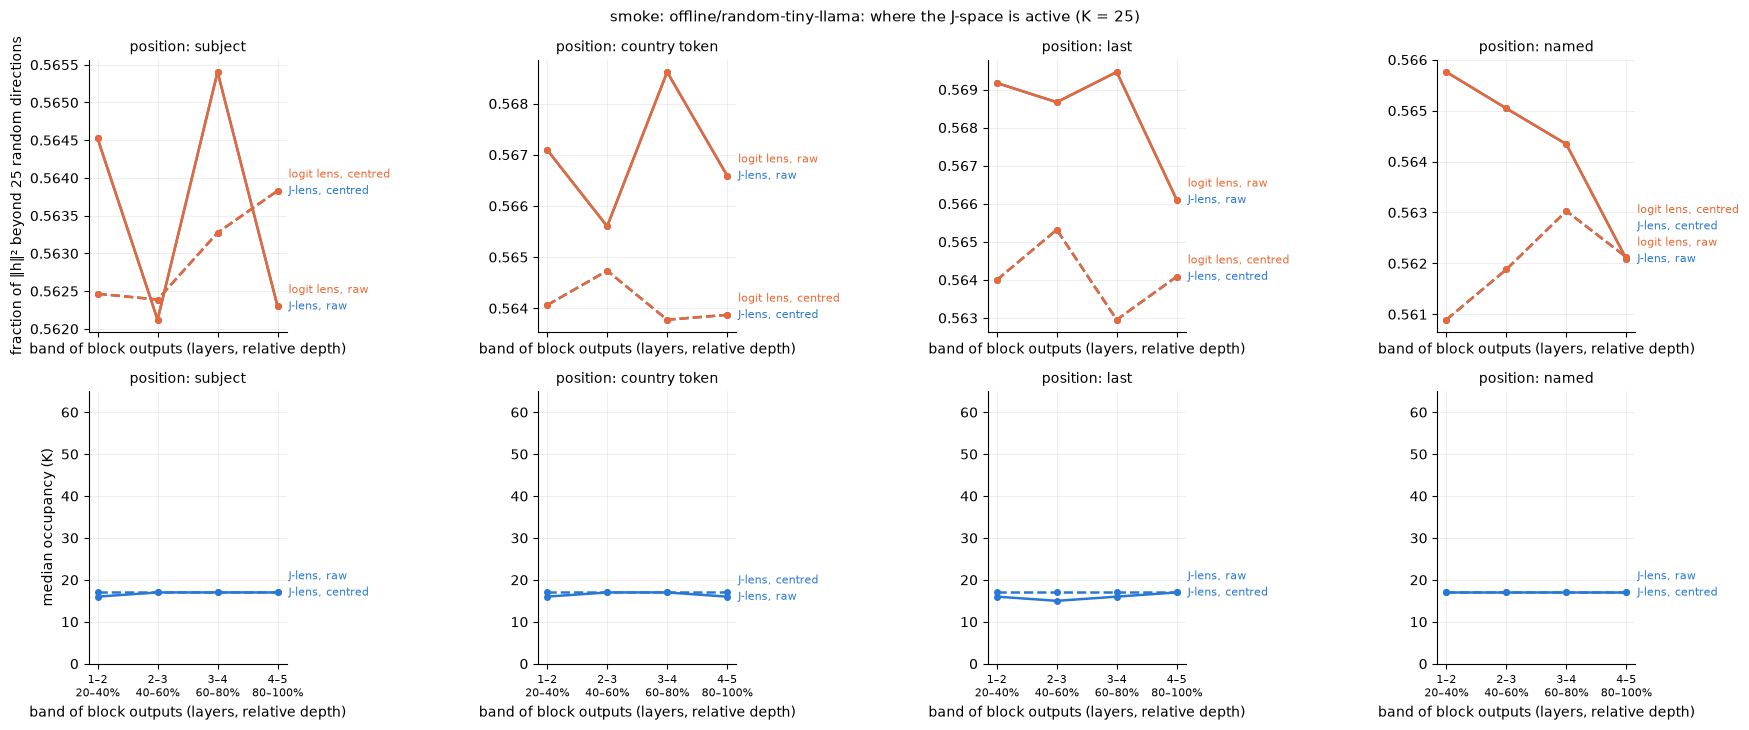

In [10]:
def label_ends(ax, ends, gap=0.06):
    # Write each line's name at its right end, nudged apart vertically (in place of a legend).
    lo, hi = ax.get_ylim()
    placed = []
    ends = [(min(max(y, lo), hi), text, color) for y, text, color in ends if np.isfinite(y)]
    for y, text, color in sorted(ends):
        y = max(y, placed[-1] + gap * (hi - lo)) if placed else y
        placed.append(y)
        ax.annotate(text, xy=(1.01, y), xycoords=("axes fraction", "data"), color=color, fontsize=8,
                    va="center", annotation_clip=False)


def band_axes(ax, ylabel=None):
    ax.set_xticks(range(len(BAND_NAMES)), BAND_TICKS, fontsize=8)
    ax.set_xlabel("band of block outputs (layers, relative depth)")
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)


position_of = sites.position.to_numpy()
layer_index = {layer: i for i, layer in enumerate(LAYERS)}


def band_layer_means(values, rows):
    """values [layers, rows] -> per band: mean over its layers of the mean over rows."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        per_layer = np.nanmean(values[:, rows].astype(np.float64), axis=1)
    return {band: per_layer[[layer_index[layer] for layer in layers]].mean() for band, layers in BANDS.items()}


kh = K_GRID.index(K_HEADLINE)
records = []
for v, variant in enumerate(VARIANTS):
    for pos in POSITIONS:
        rows = np.flatnonzero(position_of == pos)
        occ = np.median(payload["occupancy"][v][:, :, rows], axis=2)  # [layers, 2]
        fractions = {name: band_layer_means(ROWS["fraction of norm"][v, :, kh, ARMS.index(name)], rows)
                     for name in DICTIONARIES}
        for band, layers in BANDS.items():
            li = [layer_index[layer] for layer in layers]
            records.append({
                "variant": variant, "position": pos, "band": band,
                "median occupancy": np.median(occ[li, 0]),
                "median occupancy vs best of V random": np.median(occ[li, 1]),
                "J fraction of norm": fractions["J-lens"][band],
                "logit fraction": fractions["logit lens"][band],
                "best of V random": fractions["random"][band],
                "25 random directions": K_HEADLINE / D_MODEL,
            })
active = pd.DataFrame(records)
active["J excess over random set"] = active["J fraction of norm"] - K_HEADLINE / D_MODEL
active["logit excess over random set"] = active["logit fraction"] - K_HEADLINE / D_MODEL
display(active.set_index(["variant", "position", "band"]).round(3))

fig, axes = plt.subplots(2, len(POSITIONS), figsize=(4.4 * len(POSITIONS), 7.4), sharex=True)
for col, pos in enumerate(POSITIONS):
    for row, (metric, ylabel) in enumerate((("J excess over random set", f"fraction of ‖h‖² beyond {K_HEADLINE} random directions"),
                                            ("median occupancy", "median occupancy (K)"))):
        ax = axes[row, col]
        ends = []
        for variant, style in (("raw", "-"), ("centred", "--")):
            sub = active[active.variant.eq(variant) & active.position.eq(pos)].set_index("band").loc[BAND_NAMES]
            ax.plot(range(len(BAND_NAMES)), sub[metric], style, color=COLORS["J-lens"], marker="o", ms=4, lw=1.8)
            if row == 0:
                lsub = sub["logit excess over random set"]
                ax.plot(range(len(BAND_NAMES)), lsub, style, color=COLORS["logit lens"], marker="o", ms=4, lw=1.8)
                ends.append((lsub.iloc[-1], f"logit lens, {variant}", COLORS["logit lens"]))
            ends.append((sub[metric].iloc[-1], f"J-lens, {variant}", COLORS["J-lens"]))
        if row == 1:
            ax.set_ylim(0, K_MAX + 1)
        label_ends(ax, ends)
        band_axes(ax, ylabel if col == 0 else None)
        ax.set_title(f"position: {pos}", fontsize=10)
fig.suptitle(f"{SOURCE_MODE}: {payload['manifest']['model']}: where the J-space is active (K = {K_HEADLINE})", fontsize=11)
fig.tight_layout(w_pad=7)
fig.savefig(RUN_DIR / "jspace_active.png", dpi=140)
plt.show()

Fraction of norm against K at the middle layer of each band: J-lens and logit-lens
dictionaries, the best-of-V random control and K random directions (`K/d`); raw activations,
last subject token and named country token.

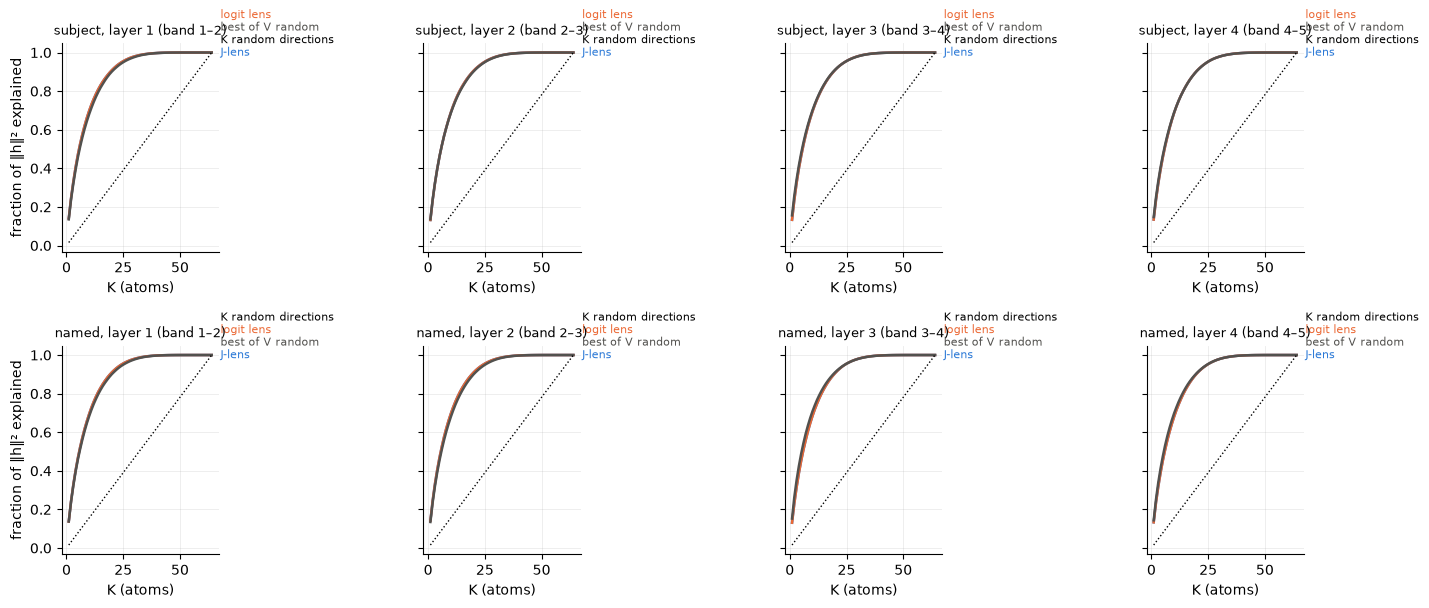

In [11]:
fig, axes = plt.subplots(2, len(BAND_NAMES), figsize=(3.6 * len(BAND_NAMES), 6.2), sharey=True, squeeze=False)
ks = np.arange(1, payload["k_max"] + 1)
for row, pos in enumerate(["subject", "named"]):
    for ax, band in zip(axes[row], BAND_NAMES, strict=True):
        layer = BANDS[band][(len(BANDS[band]) - 1) // 2]
        ends = []
        for a, name in enumerate(DICTIONARIES):
            curve = payload["curves"][VARIANTS.index("raw"), layer_index[layer], POSITIONS.index(pos), a]
            ax.plot(ks, curve, color=COLORS[name], lw=1.8)
            ends.append((curve[-1], {"random": "best of V random"}.get(name, name), COLORS[name]))
        ax.plot(ks, ks / D_MODEL, color="black", lw=1, ls=":")
        ends.append((ks[-1] / D_MODEL, "K random directions", "black"))
        label_ends(ax, ends)
        ax.set_title(f"{pos}, layer {layer} (band {band.replace('-', '–')})", fontsize=9)
        ax.set_xlabel("K (atoms)")
        ax.grid(alpha=0.25, lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)
    axes[row, 0].set_ylabel("fraction of ‖h‖² explained")
fig.tight_layout(w_pad=6)
plt.show()

## 3. Per-prompt values and paired bootstrap

Every concept metric below is a per-row value, averaged over the layers of a band, so each latent
prompt is one unit with one value per arm. The table value is the mean over prompts; the
interval resamples prompts with replacement (`BOOTSTRAP_OPTIONS`), the same draws for every arm,
and computes each difference on the same draw. `degenerate` means the bootstrap distribution is
constant (for instance identical arms in smoke mode); `no_supported_units` means no prompt had a
value (a country without a whole-token spelling has no atom metric). Intervals are pointwise and
condition on the named centroids and on the other rows that define each row's consistency. The
headline uses raw activations, K = 25 and all candidates; nothing here is selected from the
results.

In [12]:
CONCEPT_METRICS = {
    "named-centroid accuracy": ARMS, "named-centroid accuracy within language": ARMS,
    "consistency": ARMS, "consistency vs same language": ARMS,
    "country atom selected": ["J-lens", "logit lens"], "control atom selected": ["J-lens", "logit lens"],
    "fraction of norm": DICTIONARIES,
}
COMPARISONS = {
    "J-lens": [("J-lens", "full h"), ("J-lens", "logit lens"), ("J-lens", "random"), ("J-lens", "non-J part")],
}
prompt_of = sites.prompt_id.to_numpy()


def unit_values(metric, position, k=K_HEADLINE, variant="raw", subset="all candidates"):
    """Long frame unit/arm/band/value: per prompt, the metric averaged over the band's layers."""
    v, ki = VARIANTS.index(variant), K_GRID.index(k)
    selected = np.isin(prompt_of, SUBSETS[subset]) | (position_of == "named")  # subsets select latent prompts
    rows = np.flatnonzero((position_of == position) & selected)
    frames = []
    for arm in CONCEPT_METRICS[metric]:
        values = ROWS[metric][v, :, ki, ARMS.index(arm)][:, rows].astype(np.float64)  # [layers, rows]
        for band, layers in BANDS.items():
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                value = np.nanmean(values[[layer_index[layer] for layer in layers]], axis=0)
            frames.append(pd.DataFrame({"unit": prompt_of[rows], "arm": arm, "band": band, "value": value}))
    return pd.concat(frames, ignore_index=True)


def point_table(metric, positions=LATENT_POSITIONS, **options):
    """Mean over prompts per position, arm and band."""
    rows = []
    for pos in positions:
        frame = unit_values(metric, pos, **options)
        for (arm, band), group in frame.groupby(["arm", "band"], sort=False):
            if len(group):
                rows.append({"position": pos, "arm": arm, "band": band, "value": group.value.mean()})
    index = pd.MultiIndex.from_product([positions, CONCEPT_METRICS[metric]], names=["position", "arm"])
    if not rows:  # an empty subset, e.g. no correct answers
        return pd.DataFrame(np.nan, index=index, columns=pd.Index(BAND_NAMES, name="band"))
    table = pd.DataFrame(rows).pivot_table(index=["position", "arm"], columns="band", values="value", dropna=False)
    return table.reindex(index=index, columns=BAND_NAMES)


bootstrap_tables = []
for metric, arms in CONCEPT_METRICS.items():
    comparisons = [(a, b) for a, b in COMPARISONS["J-lens"] if a in arms and b in arms]
    for pos in LATENT_POSITIONS:
        frame = unit_values(metric, pos)
        for band, group in frame.groupby("band", sort=False):
            scores = group.assign(cluster=group.unit, stratum="all")
            table = paired_cluster_bootstrap(scores, arms=arms, comparisons=comparisons, **BOOTSTRAP_OPTIONS)
            bootstrap_tables.append(table.assign(metric=metric, position=pos, band=band, k=K_HEADLINE,
                                                 variant="raw", subset="all candidates"))
bootstrap_ci = pd.concat(bootstrap_tables, ignore_index=True)

# The bootstrap must preserve the point estimate: mean over prompts of band means.
check = bootstrap_ci[bootstrap_ci.statistic.eq("arm")]
for metric, group in check.groupby("metric"):
    expected = point_table(metric).reset_index().melt(id_vars=["position", "arm"], var_name="band",
                                                      value_name="value")
    merged = group.merge(expected, left_on=["position", "arm", "band"], right_on=["position", "arm", "band"])
    np.testing.assert_allclose(merged.estimate, merged.value, atol=1e-9, equal_nan=True)
bootstrap_ci.to_csv(RUN_DIR / "bootstrap_intervals.csv", index=False)
print(f"{len(bootstrap_ci)} interval rows; statuses:", bootstrap_ci.status.value_counts().to_dict())


def with_ci(metric, statistic="arm", reference=""):
    """Estimate [low, high] strings per position, arm and band."""
    rows = bootstrap_ci[bootstrap_ci.metric.eq(metric) & bootstrap_ci.statistic.eq(statistic)
                        & bootstrap_ci.reference.eq(reference)]

    def fmt(row):
        if row.status != "ok":
            return f"{row.estimate:.3f} ({row.status})"
        return f"{row.estimate:.3f} [{row.ci_low:.3f}, {row.ci_high:.3f}]"

    rows = rows.assign(text=rows.apply(fmt, axis=1))
    return rows.pivot(index=["position", "arm"], columns="band", values="text").reindex(columns=BAND_NAMES)

564 interval rows; statuses: {'ok': 478, 'degenerate': 86}


## 4. Is the country in the J-space component?

Share of prompts whose 25 selected atoms include a whole-token spelling of the country, against
the prompt's control country; J-lens and logit-lens dictionaries. The `named` row is the
country token of the templates, where the name is in the input.

band                                              1-2    2-3    3-4    4-5
metric                position      arm                                   
country atom selected subject       J-lens      0.043  0.052  0.090  0.057
                                    logit lens  0.043  0.052  0.090  0.057
                      country token J-lens      0.048  0.090  0.095  0.110
                                    logit lens  0.048  0.090  0.095  0.110
                      last          J-lens      0.048  0.043  0.090  0.052
                                    logit lens  0.048  0.043  0.090  0.052
                      named         J-lens      0.043  0.045  0.077  0.045
                                    logit lens  0.043  0.045  0.077  0.045
control atom selected subject       J-lens      0.076  0.057  0.076  0.090
                                    logit lens  0.076  0.057  0.076  0.090
                      country token J-lens      0.052  0.067  0.105  0.081
                                    logit lens  0.052  0.067  0.105  0.081
                      last          J-lens      0.071  0.029  0.076  0.071
                                    logit lens  0.071  0.029  0.076  0.071
                      named         J-lens      0.070  0.057  0.068  0.084
                                    logit lens  0.070  0.057  0.068  0.084

,band,1-2,2-3,3-4,4-5
position,J-lens − logit lens,,,,
country token,J-lens,0.000 (degenerate),0.000 (degenerate),0.000 (degenerate),0.000 (degenerate)
last,J-lens,0.000 (degenerate),0.000 (degenerate),0.000 (degenerate),0.000 (degenerate)
subject,J-lens,0.000 (degenerate),0.000 (degenerate),0.000 (degenerate),0.000 (degenerate)


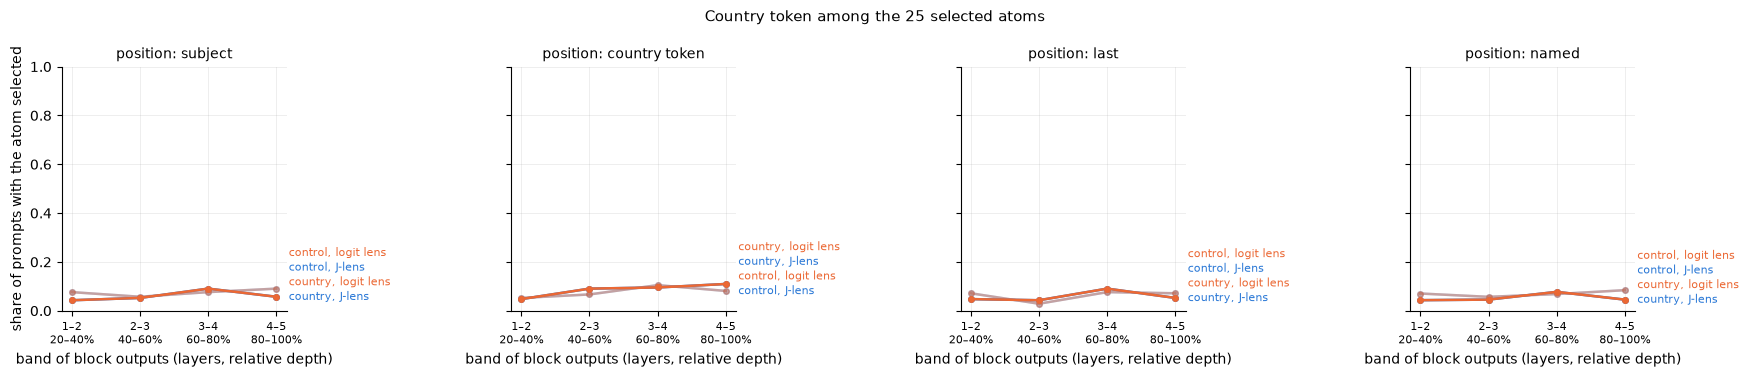

In [13]:
atoms_table = pd.concat({metric: point_table(metric, positions=POSITIONS) for metric in
                         ["country atom selected", "control atom selected"]}, names=["metric"])
display(atoms_table.round(3))
display(with_ci("country atom selected", "difference", "logit lens").rename_axis(
    index=["position", "J-lens − logit lens"]))
fig, axes = plt.subplots(1, len(POSITIONS), figsize=(4.4 * len(POSITIONS), 3.8), sharey=True)
for ax, pos in zip(axes, POSITIONS, strict=True):
    ends = []
    for name in ["J-lens", "logit lens"]:
        for metric, alpha_, text in (("country atom selected", 1.0, "country"), ("control atom selected", 0.4, "control")):
            values = atoms_table.loc[(metric, pos, name)].to_numpy(dtype=float)
            ax.plot(range(len(BAND_NAMES)), values, color=COLORS[name], alpha=alpha_, marker="o", ms=4, lw=1.8)
            ends.append((values[-1], f"{text}, {name}", COLORS[name]))
    ax.set_ylim(0, 1)
    label_ends(ax, ends)
    band_axes(ax, "share of prompts with the atom selected" if pos == POSITIONS[0] else None)
    ax.set_title(f"position: {pos}", fontsize=10)
fig.suptitle(f"Country token among the {K_HEADLINE} selected atoms", fontsize=11)
fig.tight_layout(w_pad=8)
plt.show()

## 5. Is the J-space component of the country the same across prompts?

Per prompt: mean cosine to prompts with the same country minus to prompts with a different
country, prompts from other subject families only; bottom row: shared-language countries, same
country minus a different country with the same language. Shaded: paired 95% intervals.

band                                                     1-2    2-3    3-4    4-5
metric                       position      arm                                   
consistency                  subject       J-lens      0.004  0.003  0.004  0.004
                                           logit lens  0.004  0.003  0.004  0.004
                                           random      0.003  0.003  0.004  0.004
                                           full h      0.004  0.003  0.003  0.003
                                           non-J part -0.004  0.004  0.004 -0.003
                             country token J-lens      0.000  0.001  0.000  0.002
                                           logit lens  0.000  0.001  0.000  0.002
                                           random     -0.000  0.001  0.001  0.001
                                           full h     -0.000  0.001  0.001  0.001
                                           non-J part  0.004  0.004  0.004  0.002
                             last          J-lens      0.000  0.000  0.001  0.002
                                           logit lens  0.000  0.000  0.001  0.002
                                           random     -0.000  0.000  0.002  0.002
                                           full h      0.000  0.001  0.001  0.002
                                           non-J part -0.004  0.001 -0.006  0.001
consistency vs same language subject       J-lens      0.012  0.009  0.007  0.008
                                           logit lens  0.012  0.009  0.007  0.008
                                           random      0.013  0.009  0.007  0.006
                                           full h      0.012  0.007  0.007  0.005
                                           non-J part  0.010 -0.011  0.003  0.001
                             country token J-lens      0.005  0.008  0.009  0.012
                                           logit lens  0.005  0.008  0.009  0.012
                                           random      0.005  0.009  0.009  0.009
                                           full h      0.005  0.008  0.010  0.011
                                           non-J part  0.005  0.009 -0.024  0.004
                             last          J-lens      0.003  0.008  0.004  0.010
                                           logit lens  0.003  0.008  0.004  0.010
                                           random      0.004  0.005  0.012  0.011
                                           full h      0.003  0.007  0.009  0.011
                                           non-J part -0.000  0.009 -0.004  0.003

,band,1-2,2-3,3-4,4-5
position,J-space − full h,,,,
country token,J-lens,"0.000 [-0.001, 0.001]","0.000 [-0.001, 0.001]","-0.001 [-0.002, -0.000]","0.000 [-0.000, 0.001]"
last,J-lens,"0.000 [-0.001, 0.001]","-0.000 [-0.001, 0.000]","-0.000 [-0.001, 0.001]","0.000 [-0.001, 0.001]"
subject,J-lens,"0.000 [-0.001, 0.002]","0.000 [-0.001, 0.002]","0.000 [-0.001, 0.002]","0.001 [-0.000, 0.002]"


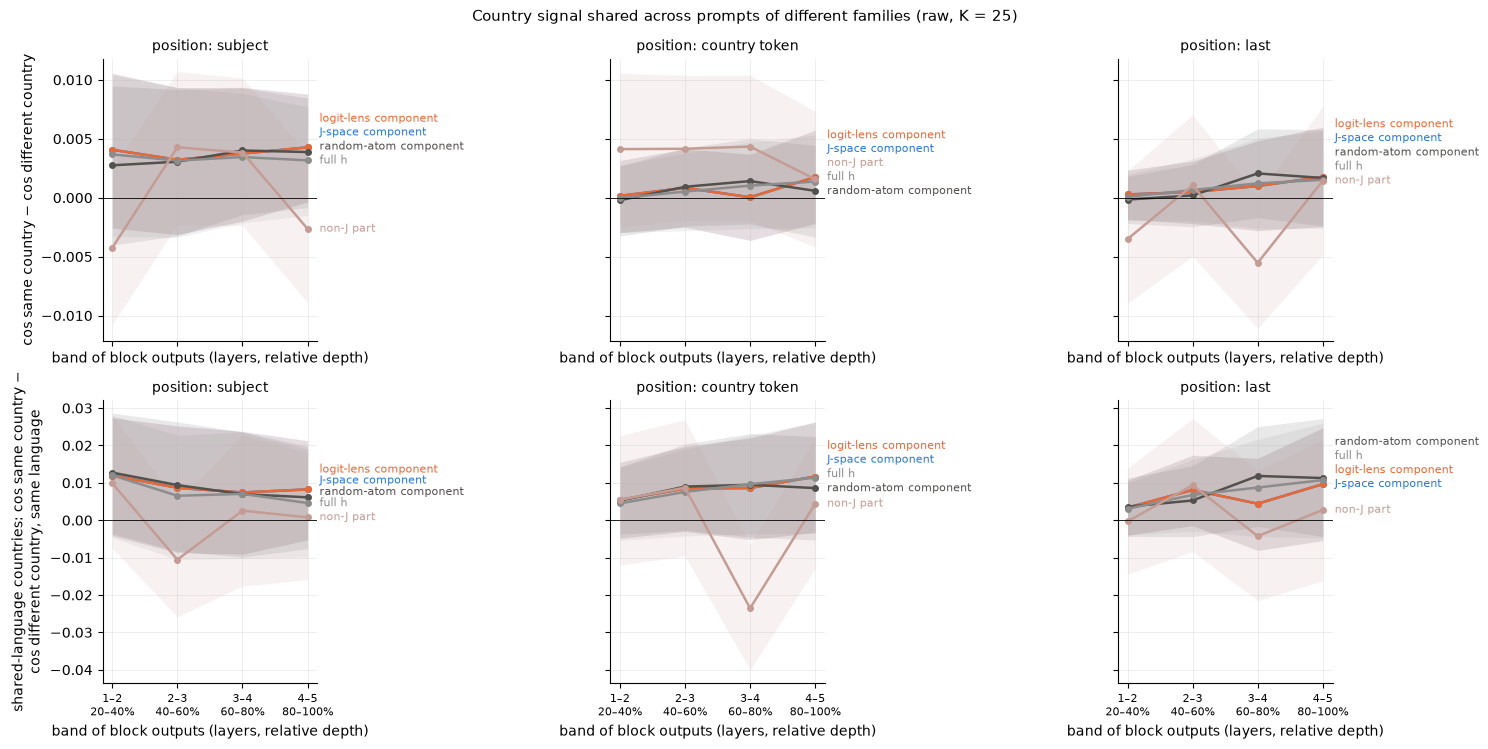

In [14]:
def ci_lines(metric, ax, pos, chance=None):
    ends = []
    rows = bootstrap_ci[bootstrap_ci.metric.eq(metric) & bootstrap_ci.statistic.eq("arm") & bootstrap_ci.position.eq(pos)]
    for arm in ARMS:
        line = rows[rows.arm.eq(arm)].set_index("band").reindex(BAND_NAMES)
        x = np.arange(len(BAND_NAMES))
        ax.plot(x, line.estimate, color=COLORS[arm], marker="o", ms=4, lw=1.8)
        ax.fill_between(x, line.ci_low.to_numpy(dtype=float), line.ci_high.to_numpy(dtype=float),
                        color=COLORS[arm], alpha=0.12, lw=0)
        ends.append((line.estimate.iloc[-1], LABELS[arm], COLORS[arm]))
    if chance is not None:
        ax.axhline(chance, color="black", lw=0.8, ls=":")
    return ends


consistency_table = pd.concat({metric: point_table(metric) for metric in
                               ["consistency", "consistency vs same language"]}, names=["metric"])
display(consistency_table.round(3))
display(with_ci("consistency", "difference", "full h").rename_axis(index=["position", "J-space − full h"]))
fig, axes = plt.subplots(2, 3, figsize=(15, 7.6), sharex=True, sharey="row")
for row_axes, (metric, ylabel) in zip(axes, [
        ("consistency", "cos same country − cos different country"),
        ("consistency vs same language", "shared-language countries: cos same country −\ncos different country, same language")],
        strict=True):
    for ax, pos in zip(row_axes, LATENT_POSITIONS, strict=True):
        ends = ci_lines(metric, ax, pos)
        ax.axhline(0, color="black", lw=0.6)
        label_ends(ax, ends, gap=0.05)
        band_axes(ax, ylabel if pos == "subject" else None)
        ax.set_title(f"position: {pos}", fontsize=10)
fig.suptitle(f"Country signal shared across prompts of different families (raw, K = {K_HEADLINE})", fontsize=11)
fig.tight_layout(w_pad=10)
fig.savefig(RUN_DIR / "jspace_consistency.png", dpi=140)
plt.show()

### Named vs latent

Each latent prompt is assigned the country whose named-template centroid (same layer, same
component) is most similar; top-1 among the countries with a centroid (chance 1/22), and within
the language group of the shared-language countries. Shaded: paired 95% intervals.

band                                                                1-2    2-3    3-4    4-5
metric                                  position      arm                                   
named-centroid accuracy                 subject       J-lens      0.043  0.029  0.038  0.033
                                                      logit lens  0.043  0.029  0.038  0.033
                                                      random      0.052  0.024  0.033  0.043
                                                      full h      0.048  0.038  0.029  0.033
                                                      non-J part  0.024  0.033  0.029  0.048
                                        country token J-lens      0.062  0.052  0.048  0.062
                                                      logit lens  0.062  0.052  0.048  0.062
                                                      random      0.071  0.062  0.071  0.067
                                                      full h      0.052  0.048  0.043  0.062
                                                      non-J part  0.038  0.048  0.052  0.033
                                        last          J-lens      0.052  0.043  0.024  0.033
                                                      logit lens  0.052  0.043  0.024  0.033
                                                      random      0.052  0.048  0.029  0.033
                                                      full h      0.043  0.043  0.033  0.038
                                                      non-J part  0.048  0.038  0.062  0.057
named-centroid accuracy within language subject       J-lens      0.404  0.383  0.319  0.362
                                                      logit lens  0.404  0.383  0.319  0.362
                                                      random      0.447  0.383  0.383  0.383
                                                      full h      0.447  0.362  0.383  0.340
                                                      non-J part  0.362  0.340  0.298  0.383
                                        country token J-lens      0.447  0.383  0.362  0.298
                                                      logit lens  0.447  0.383  0.362  0.298
                                                      random      0.489  0.362  0.468  0.383
                                                      full h      0.532  0.426  0.383  0.319
                                                      non-J part  0.340  0.277  0.340  0.404
                                        last          J-lens      0.426  0.426  0.383  0.362
                                                      logit lens  0.426  0.426  0.383  0.362
                                                      random      0.404  0.426  0.362  0.383
                                                      full h      0.426  0.426  0.383  0.426
                                                      non-J part  0.468  0.426  0.489  0.340

,band,1-2,2-3,3-4,4-5
position,J-space − full h,,,,
country token,J-lens,"0.010 [-0.010, 0.029]","0.005 [-0.019, 0.029]","0.005 [-0.019, 0.029]","0.000 [-0.014, 0.014]"
last,J-lens,"0.010 [-0.014, 0.033]","0.000 [-0.014, 0.014]","-0.010 [-0.029, 0.010]","-0.005 [-0.019, 0.010]"
subject,J-lens,"-0.005 [-0.024, 0.010]","-0.010 [-0.029, 0.010]","0.010 [-0.010, 0.029]","0.000 [-0.019, 0.019]"


,band,1-2,2-3,3-4,4-5
position,J-space − random-atom component,,,,
country token,J-lens,"-0.043 [-0.149, 0.064]","0.021 [-0.085, 0.128]","-0.106 [-0.213, 0.000]","-0.085 [-0.170, -0.021]"
last,J-lens,"0.021 [0.000, 0.064]","0.000 [-0.106, 0.106]","0.021 [-0.085, 0.128]","-0.021 [-0.106, 0.043]"
subject,J-lens,"-0.043 [-0.106, 0.000]","0.000 [-0.085, 0.085]","-0.064 [-0.191, 0.064]","-0.021 [-0.085, 0.043]"


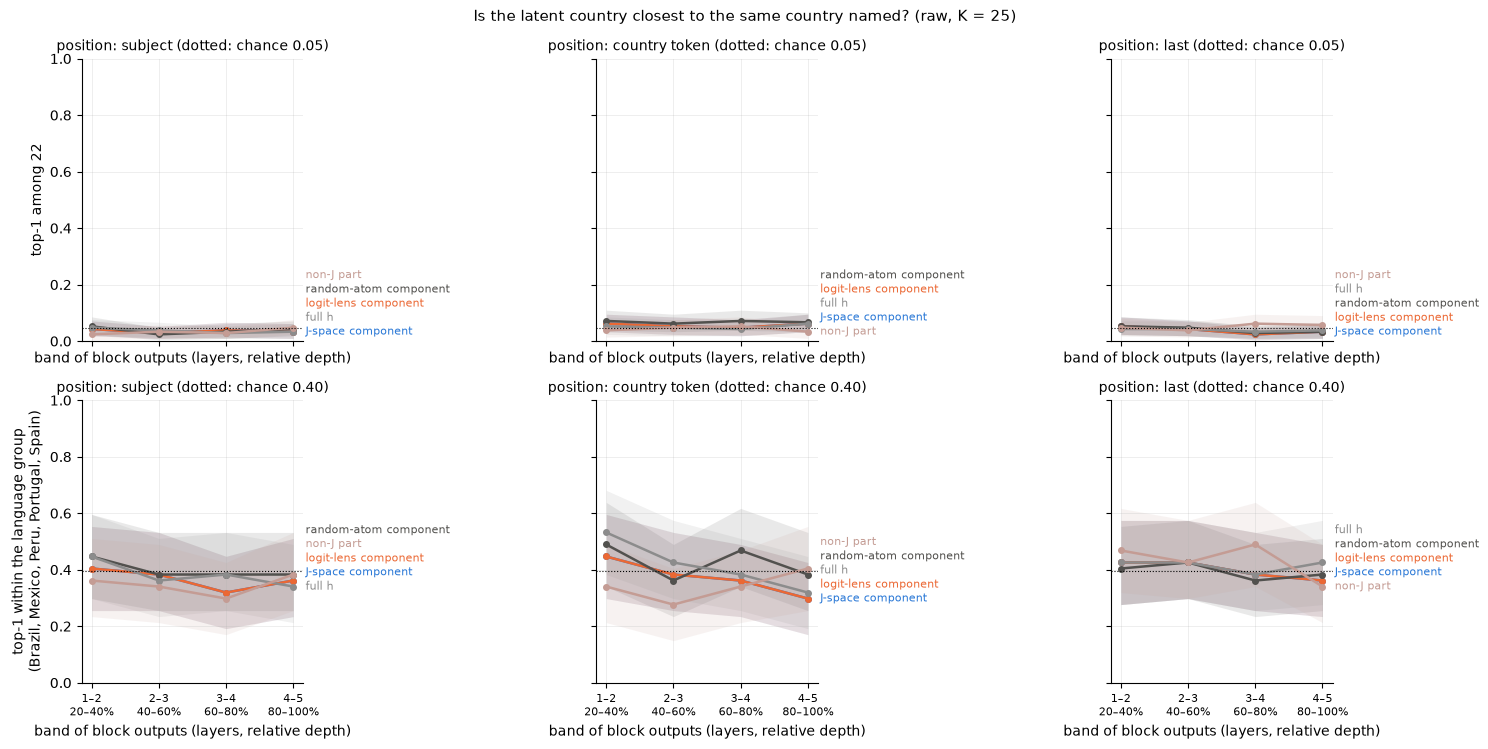

Last subject token, by subset (point estimates):


1-2    2-3    3-4    4-5
metric                                  subset                prompts arm                                   
named-centroid accuracy                 all candidates        210     J-lens      0.043  0.029  0.038  0.033
                                                                      full h      0.048  0.038  0.029  0.033
                                                                      logit lens  0.043  0.029  0.038  0.033
                                                                      random      0.052  0.024  0.033  0.043
named-centroid accuracy within language all candidates        210     J-lens      0.404  0.383  0.319  0.362
                                                                      full h      0.447  0.362  0.383  0.340
                                                                      logit lens  0.404  0.383  0.319  0.362
                                                                      random      0.447  0.383  0.383  0.383
consistency                             all candidates        210     J-lens      0.004  0.003  0.004  0.004
                                                                      full h      0.004  0.003  0.003  0.003
                                                                      logit lens  0.004  0.003  0.004  0.004
                                                                      random      0.003  0.003  0.004  0.004
named-centroid accuracy                 current model correct 0       J-lens        NaN    NaN    NaN    NaN
                                                                      full h        NaN    NaN    NaN    NaN
                                                                      logit lens    NaN    NaN    NaN    NaN
                                                                      random        NaN    NaN    NaN    NaN
named-centroid accuracy within language current model correct 0       J-lens        NaN    NaN    NaN    NaN
                                                                      full h        NaN    NaN    NaN    NaN
                                                                      logit lens    NaN    NaN    NaN    NaN
                                                                      random        NaN    NaN    NaN    NaN
consistency                             current model correct 0       J-lens        NaN    NaN    NaN    NaN
                                                                      full h        NaN    NaN    NaN    NaN
                                                                      logit lens    NaN    NaN    NaN    NaN
                                                                      random        NaN    NaN    NaN    NaN
named-centroid accuracy                 historical GPT-2 kept 138     J-lens      0.036  0.022  0.029  0.036
                                                                      full h      0.036  0.029  0.029  0.029
                                                                      logit lens  0.036  0.022  0.029  0.036
                                                                      random      0.043  0.014  0.029  0.043
named-centroid accuracy within language historical GPT-2 kept 138     J-lens      0.406  0.406  0.344  0.406
                                                                      full h      0.438  0.406  0.438  0.375
                                                                      logit lens  0.406  0.406  0.344  0.406
                                                                      random      0.438  0.406  0.406  0.438
consistency                             historical GPT-2 kept 138     J-lens      0.004  0.005  0.005  0.005
                                                                      full h      0.004  0.004  0.004  0.005
                                                                      logit lens  0.004  0.005  0.005  0.005
                                                   

In [15]:
named_table = pd.concat({metric: point_table(metric) for metric in
                         ["named-centroid accuracy", "named-centroid accuracy within language"]}, names=["metric"])
display(named_table.round(3))
display(with_ci("named-centroid accuracy", "difference", "full h").rename_axis(index=["position", "J-space − full h"]))
display(with_ci("named-centroid accuracy within language", "difference", "random").rename_axis(
    index=["position", "J-space − random-atom component"]))
shared_rows = latent[latent.position.eq("subject") & latent.country.isin(SHARED_COUNTRIES)]
chance_within = np.mean([1 / sum(LANG[o] == LANG[c] for o in COUNTRIES) for c in shared_rows.country]) \
    if len(shared_rows) else np.nan
fig, axes = plt.subplots(2, 3, figsize=(15, 7.6), sharex=True, sharey=True)
for row_axes, (metric, ylabel, chance) in zip(axes, [
        ("named-centroid accuracy", f"top-1 among {len(COUNTRIES)}", 1 / len(COUNTRIES)),
        ("named-centroid accuracy within language", f"top-1 within the language group\n({', '.join(SHARED_COUNTRIES)})",
         chance_within)], strict=True):
    for ax, pos in zip(row_axes, LATENT_POSITIONS, strict=True):
        ends = ci_lines(metric, ax, pos, chance)
        ax.set_ylim(0, 1)
        label_ends(ax, ends, gap=0.05)
        band_axes(ax, ylabel if pos == "subject" else None)
        ax.set_title(f"position: {pos} (dotted: chance {chance:.2f})", fontsize=10)
fig.suptitle(f"Is the latent country closest to the same country named? (raw, K = {K_HEADLINE})", fontsize=11)
fig.tight_layout(w_pad=10)
fig.savefig(RUN_DIR / "jspace_named_vs_latent.png", dpi=140)
plt.show()

subset_rows = []
for subset in SUBSETS:
    for metric in ["named-centroid accuracy", "named-centroid accuracy within language", "consistency"]:
        table = point_table(metric, positions=["subject"], subset=subset)
        for arm in ["J-lens", "full h", "logit lens", "random"]:
            subset_rows.append({"subset": subset, "prompts": len(SUBSETS[subset]), "metric": metric, "arm": arm,
                                **table.loc[("subject", arm)].to_dict()})
print("Last subject token, by subset (point estimates):")
display(pd.DataFrame(subset_rows).set_index(["metric", "subset", "prompts", "arm"]).round(3))

### Sensitivity to K and to centring

J-space metrics at every K of the grid, raw and centred, at the last subject token.

In [16]:
records = []
for metric in ["consistency", "consistency vs same language", "named-centroid accuracy",
               "named-centroid accuracy within language", "country atom selected"]:
    for variant in VARIANTS:
        for k in K_GRID:
            frame = unit_values(metric, "subject", k=k, variant=variant)
            frame = frame[frame.arm.eq("J-lens")]
            records += [{"metric": metric, "variant": variant, "k": k, "band": band, "value": group.value.mean()}
                        for band, group in frame.groupby("band", sort=False)]
sensitivity = pd.DataFrame(records).pivot_table(index=["metric", "variant", "k"], columns="band", values="value")
display(sensitivity.reindex(columns=BAND_NAMES).round(3))

band                                                  1-2    2-3    3-4    4-5
metric                                  variant k                             
consistency                             centred 2   0.003  0.007  0.003  0.006
                                                4   0.007  0.006  0.005  0.005
                                                8   0.011  0.006  0.006  0.003
                                                16  0.007  0.003  0.007  0.005
                                                25  0.006  0.007  0.006  0.008
                                                32  0.007  0.006  0.007  0.007
                                                64  0.007  0.006  0.007  0.006
                                        raw     2  -0.004  0.004  0.014  0.006
                                                4   0.006  0.002  0.016  0.002
                                                8   0.003  0.001  0.008  0.003
                                                16  0.004  0.006  0.003  0.003
                                                25  0.004  0.003  0.004  0.004
                                                32  0.004  0.004  0.004  0.003
                                                64  0.004  0.003  0.003  0.003
consistency vs same language            centred 2  -0.009  0.024  0.013  0.002
                                                4   0.008  0.007  0.018  0.014
                                                8   0.008  0.002  0.005  0.003
                                                16  0.013  0.010  0.007  0.008
                                                25  0.015  0.016  0.009  0.010
                                                32  0.021  0.015  0.014  0.009
                                                64  0.021  0.014  0.012  0.008
                                        raw     2  -0.014  0.001  0.017  0.004
                                                4   0.016 -0.011  0.017  0.013
                                                8   0.007 -0.007  0.009  0.007
                                                16  0.009  0.010  0.007  0.003
                                                25  0.012  0.009  0.007  0.008
                                                32  0.011  0.007  0.008  0.007
                                                64  0.012  0.007  0.007  0.005
country atom selected                   centred 2   0.000  0.005  0.000  0.000
                                                4   0.000  0.005  0.000  0.000
                                                8   0.005  0.005  0.010  0.005
                                                16  0.010  0.019  0.024  0.024
                                                25  0.038  0.029  0.038  0.057
                                                32  0.067  0.038  0.071  0.067
                                                64  0.162  0.138  0.167  0.157
                                        raw     2   0.000  0.005  0.005  0.014
                                                4   0.000  0.005  0.005  0.024
                                                8   0.005  0.010  0.014  0.024
                                                16  0.029  0.043  0.067  0.038
                                                25  0.043  0.052  0.090  0.057
                                                32  0.062  0.067  0.110  0.081
                                                64  0.162  0.157  0.233  0.162
named-centroid accuracy                 centred 2   0.033  0.062  0.029  0.048
                                                4   0.029  0.043  0.038  0.043
                                                8   0.038  0.043  0.057  0.052
                                                16  0.052  0.043  0.052  0.033
                                                25  0.052  0.038  0.024  0.024
                                                32  0.043  0.038  0.024  0.033
                                                64

### Paired differences at the last subject token

J-space component minus each other arm, K = 25, raw, all candidates; points with 95% intervals
(statuses other than `ok` are labelled).

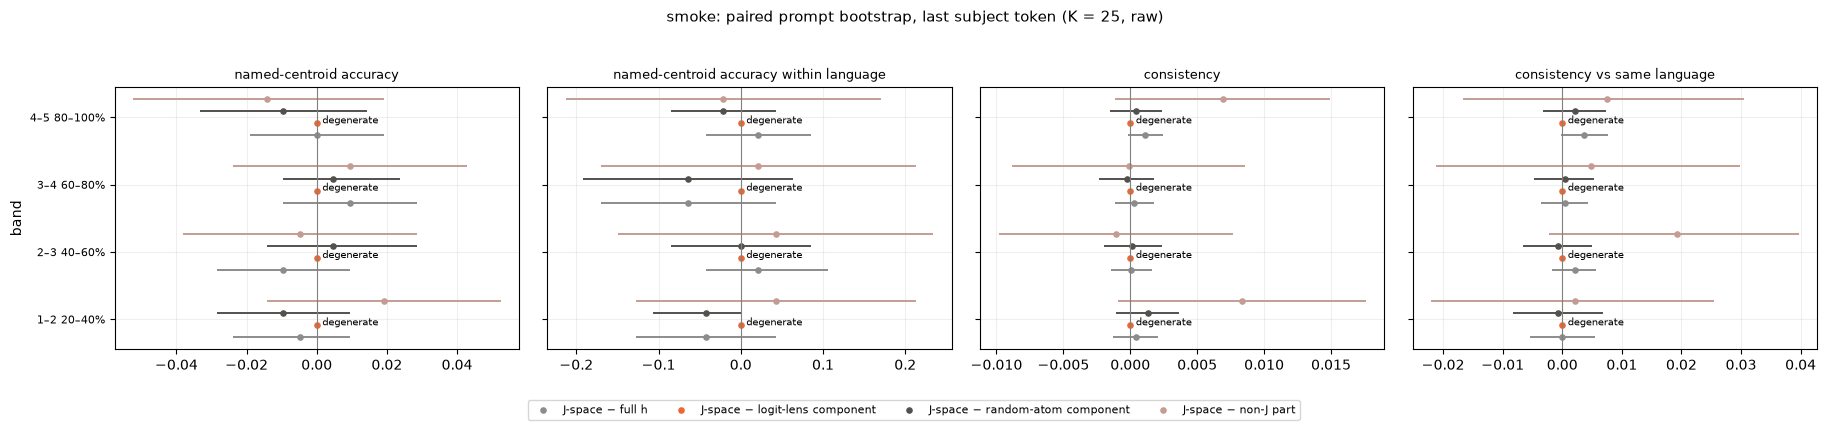

In [17]:
panels = ["named-centroid accuracy", "named-centroid accuracy within language", "consistency",
          "consistency vs same language"]
fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 4.2), sharey=True)
for ax, metric in zip(axes, panels, strict=True):
    rows = bootstrap_ci[bootstrap_ci.metric.eq(metric) & bootstrap_ci.statistic.eq("difference")
                        & bootstrap_ci.position.eq("subject")]
    for j, reference in enumerate(["full h", "logit lens", "random", "non-J part"]):
        line = rows[rows.reference.eq(reference)].set_index("band").reindex(BAND_NAMES)
        y = np.arange(len(BAND_NAMES)) + (j - 1.5) * 0.18
        ax.scatter(line.estimate, y, color=COLORS[reference], s=14, label=f"J-space − {LABELS[reference]}")
        ok = line.status.eq("ok").to_numpy()
        ax.hlines(y[ok], line.ci_low[ok], line.ci_high[ok], color=COLORS[reference], lw=1.4)
        for yy, (status, estimate) in zip(y, zip(line.status, line.estimate, strict=True), strict=True):
            if status != "ok" and np.isfinite(estimate):
                ax.annotate(status, (estimate, yy), xytext=(4, 0), textcoords="offset points", fontsize=7)
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_title(metric, fontsize=9)
    ax.set_yticks(range(len(BAND_NAMES)), [t.replace("\n", " ") for t in BAND_TICKS], fontsize=8)
    ax.grid(alpha=0.2)
axes[0].set_ylabel("band")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=8)
fig.suptitle(f"{SOURCE_MODE}: paired prompt bootstrap, last subject token (K = {K_HEADLINE}, raw)", fontsize=11)
fig.tight_layout(rect=(0, 0.08, 1, 0.95))
fig.savefig(RUN_DIR / "jspace_paired_differences.png", dpi=140)
plt.show()

## 6. Probe directions in J-space

Fraction of each difference-of-means probe `w_c` (named templates, raw activations) explained by
K atoms of each dictionary; mean over countries and the layers of each band. Intervals resample
countries (22 units), paired across dictionaries.

K random directions explain K/d: {'K=2': 0.0312, 'K=4': 0.0625, 'K=8': 0.125, 'K=16': 0.25, 'K=25': 0.3906, 'K=32': 0.5, 'K=64': 1.0}


K=2    K=4    K=8   K=16   K=25   K=32  K=64
dictionary band                                                
J-lens     1-2   0.232  0.383  0.587  0.828  0.951  0.984   1.0
           2-3   0.232  0.381  0.593  0.830  0.947  0.984   1.0
           3-4   0.235  0.381  0.587  0.827  0.947  0.985   1.0
           4-5   0.235  0.383  0.598  0.837  0.953  0.986   1.0
logit lens 1-2   0.232  0.383  0.587  0.828  0.951  0.984   1.0
           2-3   0.232  0.381  0.593  0.830  0.947  0.984   1.0
           3-4   0.235  0.381  0.587  0.827  0.947  0.985   1.0
           4-5   0.235  0.383  0.598  0.837  0.953  0.986   1.0
random     1-2   0.235  0.395  0.604  0.839  0.953  0.986   1.0
           2-3   0.236  0.393  0.612  0.842  0.951  0.984   1.0
           3-4   0.241  0.393  0.608  0.838  0.951  0.984   1.0
           4-5   0.238  0.393  0.601  0.833  0.948  0.984   1.0

,band,statistic,arm,reference,estimate,ci_low,ci_high,status,n_units
0,1-2,arm,J-lens,,0.951,0.943,0.957,ok,22
1,1-2,arm,logit lens,,0.951,0.943,0.957,ok,22
2,1-2,arm,random,,0.953,0.948,0.958,ok,22
3,1-2,difference,J-lens,random,-0.003,-0.010,0.005,ok,22
4,1-2,difference,J-lens,logit lens,0.000,NaN,NaN,degenerate,22
5,2-3,arm,J-lens,,0.947,0.939,0.954,ok,22
6,2-3,arm,logit lens,,0.947,0.939,0.954,ok,22
7,2-3,arm,random,,0.951,0.944,0.957,ok,22
8,2-3,difference,J-lens,random,-0.004,-0.012,0.005,ok,22
9,2-3,difference,J-lens,logit lens,0.000,NaN,NaN,degenerate,22


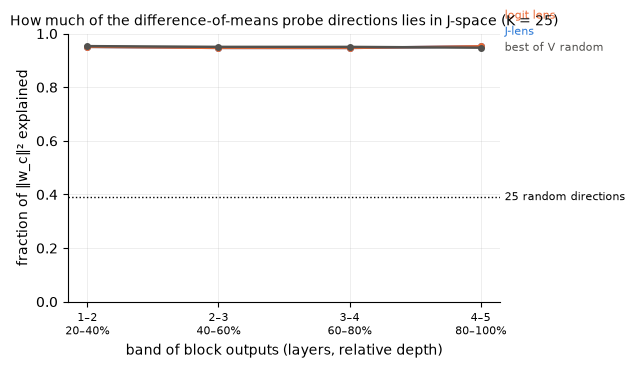

In [18]:
probe_fve = payload["probe_fve"]  # [layers, dictionaries, countries, K_MAX]
records = []
for a, name in enumerate(DICTIONARIES):
    for band, layers in BANDS.items():
        li = [layer_index[layer] for layer in layers]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            curve = np.nanmean(probe_fve[li, a], axis=(0, 1))
        records.append({"dictionary": name, "band": band, **{f"K={k}": curve[k - 1] for k in K_GRID}})
probe_table = pd.DataFrame(records).set_index(["dictionary", "band"])
print("K random directions explain K/d:", {f"K={k}": round(k / D_MODEL, 4) for k in K_GRID})
display(probe_table.round(3))
probe_ci = []
for band, layers in BANDS.items():
    li = [layer_index[layer] for layer in layers]
    values = probe_fve[li][:, :, :, K_HEADLINE - 1].mean(0)  # [dictionaries, countries]
    scores = pd.DataFrame([{"unit": c, "cluster": c, "stratum": "all", "arm": name, "value": values[a, i]}
                           for a, name in enumerate(DICTIONARIES) for i, c in enumerate(COUNTRIES)])
    probe_ci.append(paired_cluster_bootstrap(
        scores, arms=DICTIONARIES, comparisons=[("J-lens", "random"), ("J-lens", "logit lens")],
        **BOOTSTRAP_OPTIONS).assign(band=band, k=K_HEADLINE))
probe_ci = pd.concat(probe_ci, ignore_index=True)
display(probe_ci[["band", "statistic", "arm", "reference", "estimate", "ci_low", "ci_high", "status", "n_units"]]
        .round(3))
probe_ci.to_csv(RUN_DIR / "probe_bootstrap_intervals.csv", index=False)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ends = []
for name in DICTIONARIES:
    values = probe_table.loc[name].loc[BAND_NAMES, f"K={K_HEADLINE}"].to_numpy()
    ax.plot(range(len(BAND_NAMES)), values, color=COLORS[name], marker="o", ms=4, lw=1.8)
    ends.append((values[-1], {"random": "best of V random"}.get(name, name), COLORS[name]))
ax.axhline(K_HEADLINE / D_MODEL, color="black", lw=1, ls=":")
ends.append((K_HEADLINE / D_MODEL, f"{K_HEADLINE} random directions", "black"))
ax.set_ylim(0, 1)
label_ends(ax, ends)
band_axes(ax, "fraction of ‖w_c‖² explained")
ax.set_title(f"How much of the difference-of-means probe directions lies in J-space (K = {K_HEADLINE})", fontsize=10)
fig.tight_layout()
plt.show()

## 7. How much a concept's projection varies across prompts

For each country separately, over all its prompts at one position and layer, raw activations,
K = 25, no comparison with other countries:

* **Along the concept's own direction**: `a / ‖h‖` with `a = h · v̂_c`, `v̂_c` the unit J-lens
  vector of the country's primary token (the leading-space spelling where it is one token);
  mean, standard deviation and coefficient of variation `sd(a) / mean(a)` over the country's
  prompts. Controls: the logit-lens direction of the same token, a random unit direction.
* **The whole component**: relative dispersion `E‖h_J − mean_c h_J‖² / E‖h_J‖²` (0: the same
  vector in every prompt, 1: nothing shared), also for the logit-lens component and `h`.
* **The share of the norm in J-space** `‖h_J‖² / ‖h‖²` and **the concept's coordinate** (the
  coefficient of the country's atom, any whole-token spelling, over `‖h‖`): share of prompts
  where it is non-zero, its mean and CV where present.

Countries with at least 5 prompts at the position; medians over countries, then means over the
layers of a band.

position
country token    22
last             22
named            22
subject          22


J-lens direction: mean fraction  J-lens direction: sd fraction  J-lens direction: cv  logit-lens direction: mean fraction  logit-lens direction: sd fraction  logit-lens direction: cv  random direction: mean fraction  \
position      band                                                                                                                                                                                                                            
subject       1-2                             0.017                          0.094                 1.371                                0.017                              0.094                     1.371                           -0.002   
              2-3                             0.010                          0.086                 1.286                                0.010                              0.086                     1.286                           -0.016   
              3-4                             0.014                          0.078                 0.878                                0.014                              0.078                     0.878                           -0.017   
              4-5                             0.017                          0.065                 0.850                                0.017                              0.065                     0.850                           -0.008   
country token 1-2                            -0.010                          0.053                 0.550                               -0.010                              0.053                     0.550                           -0.037   
              2-3                            -0.002                          0.051                 0.583                               -0.002                              0.051                     0.583                           -0.039   
              3-4                             0.004                          0.051                 0.597                                0.004                              0.051                     0.597                           -0.046   
              4-5                            -0.000                          0.056                 0.849                               -0.000                              0.056                     0.849                           -0.033   
last          1-2                            -0.029                          0.042                 0.527                               -0.029                              0.042                     0.527                           -0.001   
              2-3                            -0.017                          0.045                 0.712                               -0.017                              0.045                     0.712                            0.014   
              3-4                             0.020                          0.050                 0.785                                0.020                              0.050                     0.785                            0.006   
              4-5                             0.002                          0.056                 0.677                                0.002                              0.056                     0.677                           -0.019   
named         1-2                            -0.030                          0.062                 0.684                               -0.030                              0.062                     0.684                           -0.028   
              2-3                            -0.024                          0.067                 0.982                               -0.024                              0.067                     0.982                           -0.033   
              3-4                            -0.009                          0.074                 1.199                               -0.009                              0.074                    

J-space: fraction of norm  J-space: fraction of norm cv  J-space: coordinate present  logit-lens: fraction of norm  logit-lens: fraction of norm cv  logit-lens: coordinate present  J-space: coordinate mean (present)  \
position      band                                                                                                                                                                                                                            
subject       1-2                       0.956                         0.012                         0.00                         0.956                            0.012                            0.00                               0.229   
              2-3                       0.954                         0.015                         0.00                         0.954                            0.015                            0.00                               0.196   
              3-4                       0.956                         0.013                         0.00                         0.956                            0.013                            0.00                               0.260   
              4-5                       0.952                         0.013                         0.00                         0.952                            0.013                            0.00                               0.269   
country token 1-2                       0.957                         0.011                         0.00                         0.957                            0.011                            0.00                               0.276   
              2-3                       0.956                         0.010                         0.00                         0.956                            0.010                            0.00                               0.225   
              3-4                       0.959                         0.010                         0.00                         0.959                            0.010                            0.00                               0.341   
              4-5                       0.958                         0.009                         0.00                         0.958                            0.009                            0.00                               0.288   
last          1-2                       0.960                         0.010                         0.00                         0.960                            0.010                            0.00                               0.227   
              2-3                       0.959                         0.011                         0.00                         0.959                            0.011                            0.00                               0.205   
              3-4                       0.960                         0.011                         0.00                         0.960                            0.011                            0.00                               0.250   
              4-5                       0.957                         0.011                         0.00                         0.957                            0.011                            0.00                               0.384   
named         1-2                       0.957                         0.012                         0.00                         0.957                            0.012                            0.00                               0.142   
              2-3                       0.957                         0.012                         0.00                         0.957                            0.012                            0.00                               0.203   
              3-4                       0.955                         0.012                         0.05                         0.955                            0.012                            0

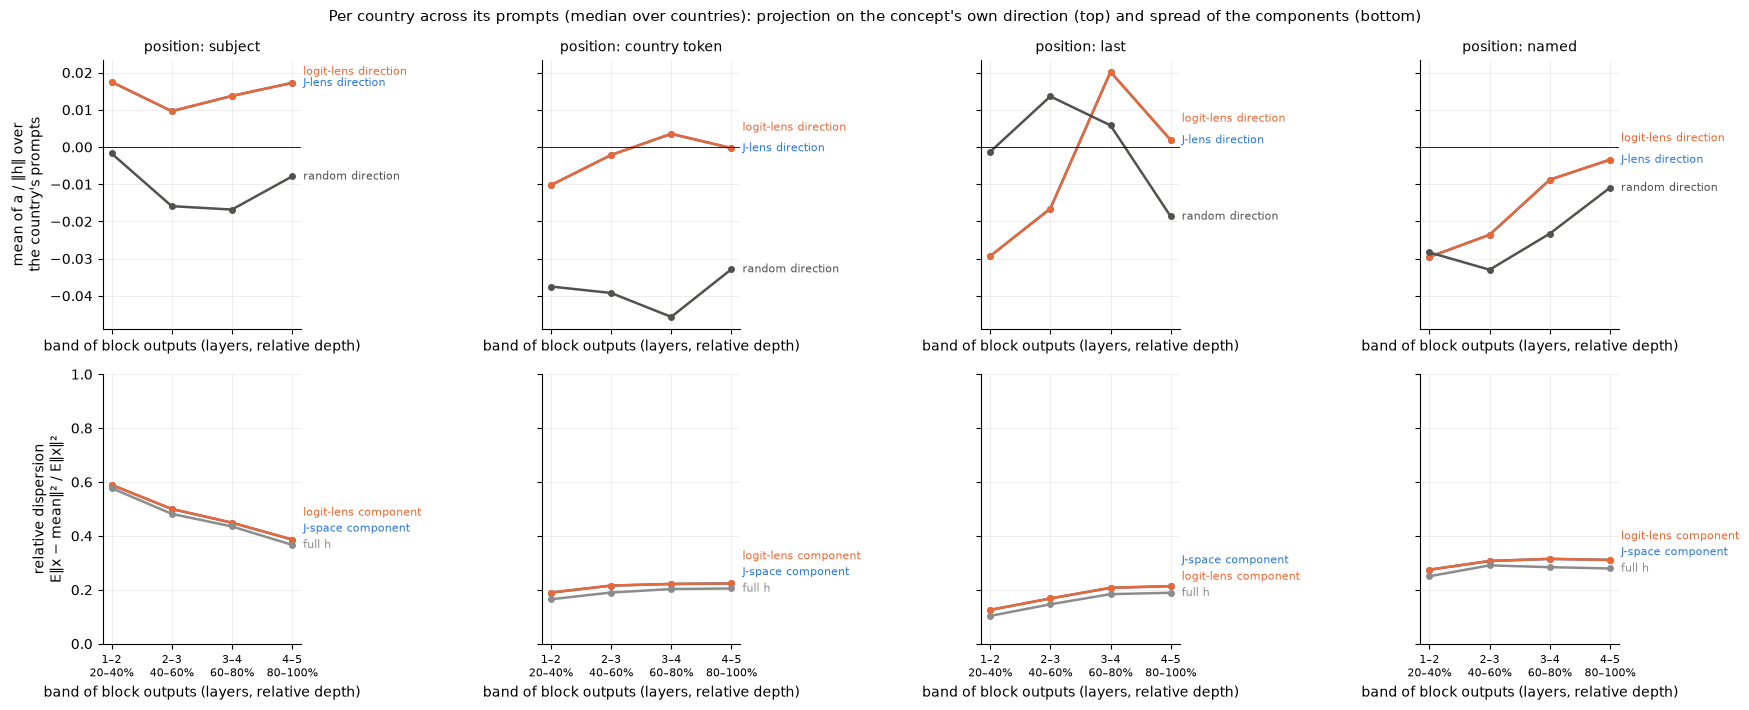

In [19]:
MIN_PROMPTS = 5
records = []
country_of = sites.country.to_numpy()
direction_names = ["J-lens direction", "logit-lens direction", "random direction"]
component_names = ["J-space component", "logit-lens component", "full h"]
for li, layer in enumerate(LAYERS):
    frame = pd.DataFrame({"position": position_of, "country": country_of})
    for d_, name in enumerate(direction_names):
        frame[name] = payload["projections"][li, d_]
    frame["J-space share"], frame["logit-lens share"] = payload["shares"][li]
    frame["J-space coordinate"], frame["logit-lens coordinate"] = payload["coordinates"][li]
    for (pos, country), group in frame.groupby(["position", "country"]):
        if len(group) < MIN_PROMPTS:
            continue
        record = {"layer": layer, "position": pos, "country": country, "prompts": len(group)}
        for name in direction_names:
            a = group[name]
            record[f"{name}: mean fraction"] = a.mean()
            record[f"{name}: sd fraction"] = a.std()
            record[f"{name}: cv"] = a.std() / abs(a.mean()) if a.mean() else np.nan
        g_ = POSITIONS.index(pos) * len(COUNTRIES) + COUNTRIES.index(country)
        for c_, name in enumerate(component_names):
            record[f"{name}: relative dispersion"] = payload["dispersion"][li, c_, g_]
        for space in ["J-space", "logit-lens"]:
            share = group[f"{space} share"]
            record[f"{space}: fraction of norm"] = share.mean()
            record[f"{space}: fraction of norm cv"] = share.std() / share.mean()
            coordinate = group[f"{space} coordinate"].dropna()
            present = coordinate[coordinate > 0]
            record[f"{space}: coordinate present"] = (coordinate > 0).mean() if len(coordinate) else np.nan
            if len(present) >= 2:
                record[f"{space}: coordinate mean (present)"] = present.mean()
                record[f"{space}: coordinate cv (present)"] = present.std() / present.mean()
        records.append(record)
variance = pd.DataFrame(records)
variance["band"] = variance.layer.map({layer: band for band, layers in BANDS.items() for layer in layers})
print(variance.groupby("position").country.nunique().rename(f"countries with >= {MIN_PROMPTS} prompts").to_string())
by_band = variance.drop(columns="country").groupby(["position", "band", "layer"]).median().groupby(
    ["position", "band"]).mean()
display(by_band[[f"{d}: {s}" for d in direction_names for s in ("mean fraction", "sd fraction", "cv")]
                + [f"{c}: relative dispersion" for c in component_names]]
        .reindex(POSITIONS, level="position").reindex(BAND_NAMES, level="band").round(3))
display(by_band[[c for c in by_band.columns if c.startswith(("J-space:", "logit-lens:"))]]
        .reindex(POSITIONS, level="position").reindex(BAND_NAMES, level="band").round(3))

fig, axes = plt.subplots(2, len(POSITIONS), figsize=(4.4 * len(POSITIONS), 7.2), sharex=True, sharey="row")
for ax, pos in zip(axes[0], POSITIONS, strict=True):
    ends = []
    for name, color in zip(direction_names, [COLORS["J-lens"], COLORS["logit lens"], COLORS["random"]], strict=True):
        values = by_band.loc[pos].reindex(BAND_NAMES)[f"{name}: mean fraction"].to_numpy()
        ax.plot(range(len(BAND_NAMES)), values, color=color, marker="o", ms=4, lw=1.8)
        ends.append((values[-1], name, color))
    ax.axhline(0, color="black", lw=0.6)
    label_ends(ax, ends, gap=0.08)
    band_axes(ax, "mean of a / ‖h‖ over\nthe country's prompts" if pos == POSITIONS[0] else None)
    ax.set_title(f"position: {pos}", fontsize=10)
for ax, pos in zip(axes[1], POSITIONS, strict=True):
    ends = []
    for name, color in zip(component_names, [COLORS["J-lens"], COLORS["logit lens"], COLORS["full h"]], strict=True):
        values = by_band.loc[pos].reindex(BAND_NAMES)[f"{name}: relative dispersion"].to_numpy()
        ax.plot(range(len(BAND_NAMES)), values, color=color, marker="o", ms=4, lw=1.8)
        ends.append((values[-1], name, color))
    ax.set_ylim(0, 1)
    label_ends(ax, ends)
    band_axes(ax, "relative dispersion\nE‖x − mean‖² / E‖x‖²" if pos == POSITIONS[0] else None)
fig.suptitle("Per country across its prompts (median over countries): projection on the concept's own direction "
             "(top) and spread of the components (bottom)", fontsize=11)
fig.tight_layout(w_pad=8)
plt.show()

## 8. Conclusions

The statements below are generated from the active run. They describe a readout of fixed
positions, not causal evidence that the model uses the J-space component; the paired intervals
cover prompt sampling only, not lens fitting, the random dictionary's seed or the choice among
the many bands and metrics shown.

In [20]:
def span(values, digits=0, scale=100):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if not len(values):
        return "n/a"
    lo, hi = scale * values.min(), scale * values.max()
    return f"{lo:.{digits}f}" if round(lo, digits) == round(hi, digits) else f"{lo:.{digits}f}–{hi:.{digits}f}"


def ci_text(metric, pos, band, arm="J-lens", reference=""):
    row = bootstrap_ci[bootstrap_ci.metric.eq(metric) & bootstrap_ci.position.eq(pos) & bootstrap_ci.band.eq(band)
                       & bootstrap_ci.arm.eq(arm) & bootstrap_ci.reference.eq(reference)].iloc[0]
    scale = 100 if "accuracy" in metric else 1
    unit, digits = (" pp", 1) if reference and scale == 100 else ("%", 0) if scale == 100 else ("", 3)
    if row.status != "ok":
        return f"{scale * row.estimate:+.{digits}f}{unit} ({row.status})" if reference else \
            f"{scale * row.estimate:.{digits}f}{unit}"
    sign = "+" if reference else ""
    return (f"{scale * row.estimate:{sign}.{digits}f}{unit} [{scale * row.ci_low:{sign}.{digits}f}, "
            f"{scale * row.ci_high:{sign}.{digits}f}]")


raw = active[active.variant.eq("raw")]
lines = []
if SOURCE_MODE == "smoke":
    lines.append("**Offline smoke only:** a random tiny Llama with identity Jacobians, so the J-lens and logit-lens "
                 "arms coincide and their paired differences are zero (`degenerate`). These numbers validate "
                 "execution, not trained-model behaviour.")
else:
    manifest_ = payload["manifest"]
    lines.append(f"**Model:** `{manifest_['model']}` at `{manifest_['revision']}`; dtype `{manifest_['dtype']}`; "
                 f"BOS `{manifest_['bos_policy']}`; lens `{manifest_['lens_sha256_or_identity'][:12]}`; "
                 f"{len(SUBSETS['all candidates'])} latent prompts.")
lines.append(f"**J-space size.** At K = {K_HEADLINE} the J-space component explains {span(raw['J fraction of norm'])}% "
             f"of ‖h‖² across positions and bands (raw; {K_HEADLINE} random directions: "
             f"{100 * K_HEADLINE / D_MODEL:.1f}%, best of {V} random atoms: {span(raw['best of V random'])}%). "
             f"Median occupancy {span(raw['median occupancy'], scale=1)} atoms; against the best-of-V random "
             f"control {span(raw['median occupancy vs best of V random'], scale=1)}.")
for pos in ["subject", "last"]:
    parts = [f"{band.replace('-', '–')}: J {ci_text('named-centroid accuracy', pos, band)}, "
             f"J − full h {ci_text('named-centroid accuracy', pos, band, reference='full h')}" for band in BAND_NAMES]
    lines.append(f"**Named vs latent, {pos} position** (top-1 among {len(COUNTRIES)}, chance "
                 f"{100 / len(COUNTRIES):.1f}%): " + "; ".join(parts) + ".")
parts = [f"{band.replace('-', '–')}: J {ci_text('named-centroid accuracy within language', 'subject', band)}, "
         f"J − random {ci_text('named-centroid accuracy within language', 'subject', band, reference='random')}"
         for band in BAND_NAMES]
lines.append(f"**Within a language group, subject** (chance {chance_within:.2f}): " + "; ".join(parts) + ".")
parts = [f"{band.replace('-', '–')}: J {ci_text('consistency', 'subject', band)}, "
         f"J − full h {ci_text('consistency', 'subject', band, reference='full h')}" for band in BAND_NAMES]
lines.append("**Consistency across families, subject** (cosine, same − different country): " + "; ".join(parts) + ".")
probe_k = probe_table[f"K={K_HEADLINE}"]
lines.append(f"**Probes.** At K = {K_HEADLINE} the J-space component explains {span(probe_k.loc['J-lens'])}% of a "
             f"difference-of-means probe across bands; the best-of-V random pursuit {span(probe_k.loc['random'])}%.")
display(Markdown("\n\n".join(lines)))
active.to_csv(RUN_DIR / "jspace_active.csv", index=False)
print("Cache, provenance, tables and figures:", RUN_DIR.relative_to(REPO) if RUN_DIR.is_relative_to(REPO) else RUN_DIR)

**Offline smoke only:** a random tiny Llama with identity Jacobians, so the J-lens and logit-lens arms coincide and their paired differences are zero (`degenerate`). These numbers validate execution, not trained-model behaviour.

**J-space size.** At K = 25 the J-space component explains 95–96% of ‖h‖² across positions and bands (raw; 25 random directions: 39.1%, best of 407 random atoms: 94–96%). Median occupancy 15–17 atoms; against the best-of-V random control 0–2.

**Named vs latent, subject position** (top-1 among 22, chance 4.5%): 1–2: J 4% [2, 7], J − full h -0.5 pp [-2.4, +1.0]; 2–3: J 3% [1, 5], J − full h -1.0 pp [-2.9, +1.0]; 3–4: J 4% [1, 7], J − full h +1.0 pp [-1.0, +2.9]; 4–5: J 3% [1, 6], J − full h +0.0 pp [-1.9, +1.9].

**Named vs latent, last position** (top-1 among 22, chance 4.5%): 1–2: J 5% [2, 9], J − full h +1.0 pp [-1.4, +3.3]; 2–3: J 4% [2, 7], J − full h +0.0 pp [-1.4, +1.4]; 3–4: J 2% [0, 5], J − full h -1.0 pp [-2.9, +1.0]; 4–5: J 3% [1, 6], J − full h -0.5 pp [-1.9, +1.0].

**Within a language group, subject** (chance 0.40): 1–2: J 40% [26, 55], J − random -4.3 pp [-10.6, +0.0]; 2–3: J 38% [26, 53], J − random +0.0 pp [-8.5, +8.5]; 3–4: J 32% [19, 45], J − random -6.4 pp [-19.1, +6.4]; 4–5: J 36% [23, 51], J − random -2.1 pp [-8.5, +4.3].

**Consistency across families, subject** (cosine, same − different country): 1–2: J 0.004 [-0.003, 0.011], J − full h +0.000 [-0.001, +0.002]; 2–3: J 0.003 [-0.003, 0.009], J − full h +0.000 [-0.001, +0.002]; 3–4: J 0.004 [-0.002, 0.009], J − full h +0.000 [-0.001, +0.002]; 4–5: J 0.004 [-0.000, 0.009], J − full h +0.001 [-0.000, +0.002].

**Probes.** At K = 25 the J-space component explains 95% of a difference-of-means probe across bands; the best-of-V random pursuit 95%.

Cache, provenance, tables and figures: runs/model-agnostic-latent-bridge-jspace/e3c45d76e265b3a8e90f


### Conclusions of this version

The committed outputs are the offline smoke run: the pipeline executes end to end, per-row
metrics and their bootstrap intervals reproduce the table point estimates, and identical J-lens
and logit-lens arms give zero paired differences flagged `degenerate`. Trained-model conclusions
need a `pretrained` run (or its cache); the GPT-2 XL notebook's results are the reference for
what to expect there, up to the pursuit, K and prompt-set differences listed at the top.